In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from nilearn.datasets import fetch_atlas_harvard_oxford
from matplotlib import pyplot as plt
from scipy.stats import spearmanr

In [2]:
CONDITIONS = [
    "food_baseline",
    "social_baseline",
    "flowers_baseline",
    "food_fasting",
    "social_fasting",
    "flowers_fasting",
    "food_isolation",
    "social_isolation",
    "flowers_isolation",
]
STIMULUS = {condition: condition.split("_")[0] for condition in CONDITIONS}
SESSION = {condition: condition.split("_")[1] for condition in CONDITIONS}


# These are the two conditions whose stimulus matches the deprived need.
MOTIVATIONALLY_RELEVANT = {
    "food_fasting",
    "social_isolation",
}

In [3]:
def clean_roi_name(roi):
    """
    Remove a trailing .nii from ROI names while preserving spaces,
    commas, apostrophes, and underscores.
    """
    roi = str(roi).strip()

    if roi.endswith(".nii"):
        roi = roi[:-4]

    return roi

In [4]:
df = pd.read_csv('probing_rsa_fasting_social_isolation/results/rdms_thresh_80/rdm_metadata.csv')
df['roi'] = df['roi'].apply(clean_roi_name)
df

,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Frontal Pole,True,5709,0.822385,"['run1', 'run2', 'run5', 'run6']"
1,sub-SAXSISO01,Insular Cortex,True,977,1.000000,"['run1', 'run2', 'run5', 'run6']"
2,sub-SAXSISO01,Superior Frontal Gyrus,True,2208,0.937978,"['run1', 'run2', 'run5', 'run6']"
3,sub-SAXSISO01,Middle Frontal Gyrus,True,2224,0.982332,"['run1', 'run2', 'run5', 'run6']"
4,sub-SAXSISO01,"Inferior Frontal Gyrus, pars triangularis",True,605,0.946792,"['run1', 'run2', 'run5', 'run6']"
...,...,...,...,...,...,...
2363,sub-SAXSISO42,HN,False,3,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2364,sub-SAXSISO42,HTH,True,133,0.963768,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2365,sub-SAXSISO42,MN,True,11,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
2366,sub-SAXSISO42,STH,True,19,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"


In [5]:
# Lets add which dataset this roi came from so we wont mix them

midbrai_roi = roi_labels = ["Pu", "Ca", "NAC", "EXA", "GPe", "GPi", "RN", "SNr", "PBP", "VeP", "HN", "HTH", "MN", "STH", "SNc_VTA"]

cortical_roi = fetch_atlas_harvard_oxford("cort-maxprob-thr0-2mm").labels
subcortical_roi = fetch_atlas_harvard_oxford("sub-maxprob-thr0-2mm").labels

cortical_roi.remove("Background")
subcortical_roi.remove("Background")

subcortical_roi = [roi.removeprefix("Left ").removeprefix("Right ") for roi in subcortical_roi]

[fetch_atlas_harvard_oxford] Dataset found in /home/anpa/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Dataset found in /home/anpa/nilearn_data/fsl


In [6]:
df['atlas'] = np.where(df['roi'].isin(cortical_roi), 'cortical', 
                       np.where(df['roi'].isin(subcortical_roi), 'subcortical', 
                                np.where(df['roi'].isin(midbrai_roi), 'midbrain', 'unknown')))

In [7]:
df.atlas.value_counts()

atlas
cortical       1536
midbrain        480
subcortical     352
Name: count, dtype: int64

In [8]:
df.query('included').atlas.value_counts()

atlas
cortical       1226
midbrain        430
subcortical     316
Name: count, dtype: int64

In [9]:
rdms = np.load('probing_rsa_fasting_social_isolation/results/rdms_thresh_80/crossnobis_rdms.npz')
rdms.keys()

KeysView(NpzFile 'probing_rsa_fasting_social_isolation/results/rdms_thresh_80/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions)

In [10]:
display(
    df.query('included').groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .sort_values(['atlas', 'n_participants'])
)


,atlas,roi,n_participants
12,cortical,"Inferior Temporal Gyrus, temporooccipital part",3
25,cortical,"Parahippocampal Gyrus, anterior division",4
7,cortical,Frontal Orbital Cortex,11
20,cortical,"Middle Temporal Gyrus, anterior division",16
33,cortical,Subcallosal Cortex,20
...,...,...,...
62,subcortical,Hippocampus,32
63,subcortical,Lateral Ventricle,32
64,subcortical,Pallidum,32
65,subcortical,Putamen,32


In [11]:
# looking at this we should exclude roi with little participants rdms

excluded_rois = (
    df.query('included')
    .groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .query('n_participants < 20')  # for example, exclude ROIs with less than 5 participants
)
excluded_rois

,atlas,roi,n_participants
7,cortical,Frontal Orbital Cortex,11
12,cortical,"Inferior Temporal Gyrus, temporooccipital part",3
20,cortical,"Middle Temporal Gyrus, anterior division",16
25,cortical,"Parahippocampal Gyrus, anterior division",4
58,subcortical,Brain-Stem,17
60,subcortical,Cerebral Cortex,13


In [12]:
# Lets create model rdms

def make_pairwise_model(name, pair_function):
    """
    Construct a symmetric model RDM from a function that assigns a
    value to each pair of conditions.
    """
    model = pd.DataFrame(
        np.zeros((len(CONDITIONS), len(CONDITIONS))),
        index=CONDITIONS,
        columns=CONDITIONS,
        dtype=float,
    )

    for i, condition_1 in enumerate(CONDITIONS):
        for j in range(i + 1, len(CONDITIONS)):
            condition_2 = CONDITIONS[j]

            value = float(
                pair_function(condition_1, condition_2)
            )

            model.loc[condition_1, condition_2] = value
            model.loc[condition_2, condition_1] = value

    model.attrs["name"] = name
    return model


baseline_vs_deprived = make_pairwise_model(
    "baseline_vs_deprived",
    lambda a, b: (
        (SESSION[a] == 'baseline')
        !=
        (SESSION[b] == 'baseline')
    ),
)

isolation_vs_baseline_and_fasting = make_pairwise_model(
    "isolation_vs_baseline_and_fasting",
    lambda a, b: (
        (SESSION[a] == 'isolation')
        !=
        (SESSION[b] == 'isolation')
    ),
)

fasting_vs_baseline_and_isolation = make_pairwise_model(
    "fasting_vs_baseline_and_isolation",
    lambda a, b: (
        (SESSION[a] == 'fasting')
        !=
        (SESSION[b] == 'fasting')
    ),
)



social_vs_food_and_flowers = make_pairwise_model(
    "social_vs_food_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'social')
        !=
        (STIMULUS[b] == 'social')
    ),
)

food_vs_social_and_flowers = make_pairwise_model(
    "food_vs_social_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'food')
        !=
        (STIMULUS[b] == 'food')
    ),
)

flowers_vs_social_and_food = make_pairwise_model(
    "flowers_vs_social_and_food",
    lambda a, b: (
        (STIMULUS[a] == 'flowers')
        !=
        (STIMULUS[b] == 'flowers')
    ),
)


social_isolation_vs_rest_model = make_pairwise_model(
    "social_isolation_vs_rest",
    lambda a, b: (
        (a == 'social_isolation')
        !=
        (b == 'social_isolation')
    ),
)

food_fasting_vs_rest_model = make_pairwise_model(
    "food_fasting_vs_rest",
    lambda a, b: (
        (a == 'food_fasting')
        !=
        (b == 'food_fasting')
    ),
)

food_fasting_and_social_isolation_vs_rest = make_pairwise_model(
    "food_fasting_and_social_isolation_vs_rest",
    lambda a, b: (
        (a in ['food_fasting', 'social_isolation'])
        !=
        (b in ['food_fasting', 'social_isolation'])
    ),
)

In [13]:
#  Category-clustering models

    # 2.1 Stimulus family
        # social_vs_food_and_flowers
        # food_vs_social_and_flowers
        # flowers_vs_social_and_food

    # 2.2 Session family
        # baseline_vs_deprived
        # isolation_vs_baseline_and_fasting
        # fasting_vs_baseline_and_isolation

# Motivation deprivation models
    # social_isolation_vs_rest_model
    # food_fasting_vs_rest_model
    # food_fasting_and_social_isolation_vs_rest

MODEL_RDMS = {
    'social_vs_food_and_flowers': social_vs_food_and_flowers,
    'food_vs_social_and_flowers': food_vs_social_and_flowers,
    'flowers_vs_social_and_food': flowers_vs_social_and_food,

    'baseline_vs_deprived': baseline_vs_deprived,
    'isolation_vs_baseline_and_fasting': isolation_vs_baseline_and_fasting,
    'fasting_vs_baseline_and_isolation': fasting_vs_baseline_and_isolation,

    'social_isolation_vs_rest_model': social_isolation_vs_rest_model,
    'food_fasting_vs_rest_model': food_fasting_vs_rest_model,
    'food_fasting_and_social_isolation_vs_rest': food_fasting_and_social_isolation_vs_rest,
}

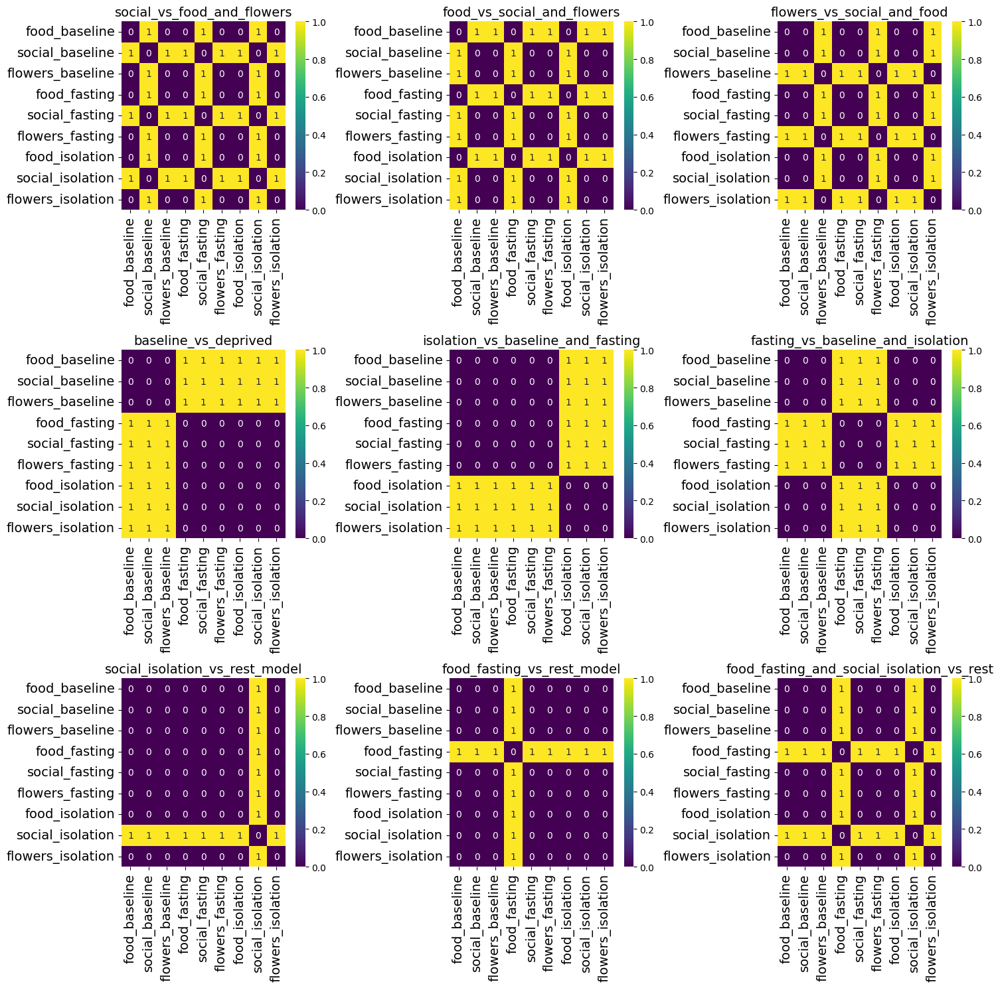

In [14]:
# plot all 9 RDMs on 3*3 grid

# increase font for x and y 
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for ax, (name, rdm) in zip(axes.flatten(), MODEL_RDMS.items()):
    sns.heatmap(rdm, annot=True, cmap="viridis", cbar=True, ax=ax)
    ax.set_title(name, fontsize=14)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
plt.tight_layout()
plt.show()

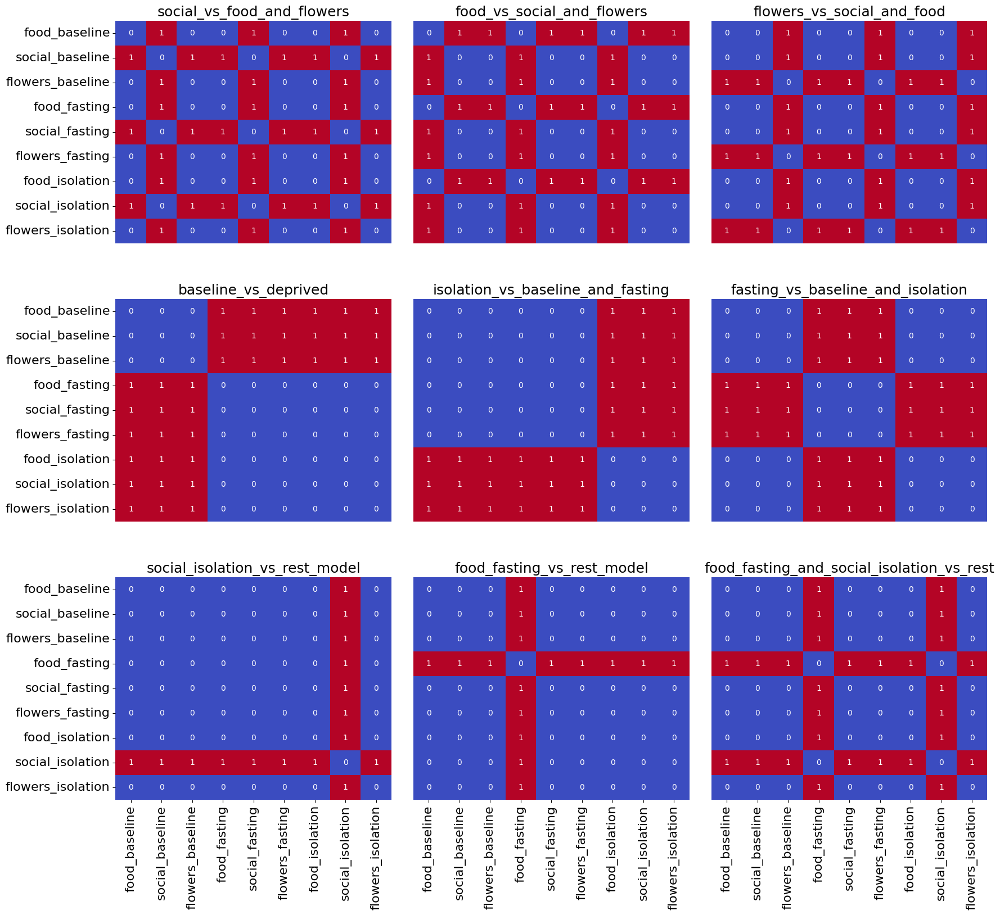

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(20, 18), sharex=True, sharey=True)

for idx, ((name, rdm), ax) in enumerate(zip(MODEL_RDMS.items(), axes.flatten())):
    row, col = divmod(idx, 3)

    sns.heatmap(
        rdm,
        annot=True,
        cmap="coolwarm",  # blue (low) -> red (high)
        cbar=False,       # no colour scale
        ax=ax,
    )

    ax.set_title(name, fontsize=18, fontweight="medium")

    if col != 0:
        ax.tick_params(left=False, labelleft=False)
    else:
        ax.tick_params(axis="y", labelsize=16, labelcolor="black")

    if row != 2:
        ax.tick_params(bottom=False, labelbottom=False)
    else:
        ax.tick_params(axis="x", labelsize=16, labelcolor="black", rotation=90)

plt.subplots_adjust(wspace=0.08, hspace=0.25)
fig.savefig("rdms.pdf", bbox_inches="tight")   # vector: stays sharp at any zoom
plt.show()

In [16]:
UPPER_TRIANGLE = np.triu_indices(
    len(CONDITIONS),
    k=1,
)

UPPER_TRIANGLE

(array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 6, 6, 7]),
 array([1, 2, 3, 4, 5, 6, 7, 8, 2, 3, 4, 5, 6, 7, 8, 3, 4, 5, 6, 7, 8, 4,
        5, 6, 7, 8, 5, 6, 7, 8, 6, 7, 8, 7, 8, 8]))

In [17]:
def vectorize_rdm(rdm):
    """
    Return the 36 unique off-diagonal entries of a 9 x 9 RDM.
    """
    ordered = rdm.loc[CONDITIONS, CONDITIONS]
    return ordered.to_numpy(dtype=float)[UPPER_TRIANGLE]

In [18]:
def compare_rdm_to_models(neural_rdm, model_rdms=MODEL_RDMS):
    neural_vector = vectorize_rdm(neural_rdm)

    return pd.Series(
        {
            name: stats.spearmanr(
                neural_vector,
                vectorize_rdm(model_rdm),
            )[0]
            for name, model_rdm in model_rdms.items()
        },
        name="spearman_rho",
    )

In [19]:
rdms["rdms"][list(rdms["subjects"]).index("sub-SAXSISO01"), list(rdms["rois"]).index("Pu.nii")]

array([[ 0.        ,  0.0501884 , -0.00102678,  0.05363569,  0.05038453,
         0.20948757,  0.32573402,  0.12635759,  0.15296879],
       [ 0.0501884 ,  0.        ,  0.01725196,  0.01909231,  0.00240232,
         0.05739799,  0.15682174,  0.02130025,  0.07626607],
       [-0.00102678,  0.01725196,  0.        ,  0.0202971 , -0.02474171,
         0.04477293,  0.24186863,  0.05753067,  0.101157  ],
       [ 0.05363569,  0.01909231,  0.0202971 ,  0.        ,  0.01250485,
         0.00589674,  0.04995241, -0.0402687 ,  0.02253497],
       [ 0.05038453,  0.00240232, -0.02474171,  0.01250485,  0.        ,
         0.0277144 ,  0.10195953, -0.05963177,  0.02111574],
       [ 0.20948757,  0.05739799,  0.04477293,  0.00589674,  0.0277144 ,
         0.        , -0.00731955, -0.1106239 , -0.0413376 ],
       [ 0.32573402,  0.15682174,  0.24186863,  0.04995241,  0.10195953,
        -0.00731955,  0.        ,  0.06033544,  0.01480729],
       [ 0.12635759,  0.02130025,  0.05753067, -0.0402687 , -0

In [20]:
excluded_rois.roi.to_list()

['Frontal Orbital Cortex',
 'Inferior Temporal Gyrus, temporooccipital part',
 'Middle Temporal Gyrus, anterior division',
 'Parahippocampal Gyrus, anterior division',
 'Brain-Stem',
 'Cerebral Cortex']

In [21]:
# Calculate one rho per participant, ROI, and model.
model_vectors = {
    name: vectorize_rdm(model_rdm)
    for name, model_rdm in MODEL_RDMS.items()
}

score_rows = []

excluded_roi_list = excluded_rois.roi.to_list()
valid_df = df.query('included & roi not in @excluded_roi_list')


for atlas, subject, roi in valid_df[['atlas', 'subject', 'roi']].itertuples(index=False):
    neural_rdm = rdms["rdms"][list(rdms["subjects"]).index(subject), list(rdms["rois"]).index(f"{roi}.nii")]
    neural_vector = neural_rdm[UPPER_TRIANGLE]

    for model_name, model_vector in model_vectors.items():
        rho = stats.spearmanr(neural_vector, model_vector)[0]

        score_rows.append({
            "atlas": atlas,
            "subject": subject,
            "roi": roi,
            "model": model_name,
            "rho": rho,
        })

participant_scores = pd.DataFrame(score_rows)
participant_scores

,atlas,subject,roi,model,rho
0,cortical,sub-SAXSISO01,Frontal Pole,social_vs_food_and_flowers,0.550834
1,cortical,sub-SAXSISO01,Frontal Pole,food_vs_social_and_flowers,0.106958
2,cortical,sub-SAXSISO01,Frontal Pole,flowers_vs_social_and_food,0.192524
3,cortical,sub-SAXSISO01,Frontal Pole,baseline_vs_deprived,-0.283439
4,cortical,sub-SAXSISO01,Frontal Pole,isolation_vs_baseline_and_fasting,-0.058827
...,...,...,...,...,...
17167,midbrain,sub-SAXSISO42,SNc_VTA,isolation_vs_baseline_and_fasting,0.732662
17168,midbrain,sub-SAXSISO42,SNc_VTA,fasting_vs_baseline_and_isolation,-0.090914
17169,midbrain,sub-SAXSISO42,SNc_VTA,social_isolation_vs_rest_model,0.334453
17170,midbrain,sub-SAXSISO42,SNc_VTA,food_fasting_vs_rest_model,0.334453


In [22]:
valid_df.roi.value_counts()

roi
Insular Cortex                               32
Middle Frontal Gyrus                         32
Superior Frontal Gyrus                       32
Inferior Frontal Gyrus, pars triangularis    32
Inferior Frontal Gyrus, pars opercularis     32
                                             ..
PBP                                          28
SNc_VTA                                      28
SNr                                          27
Frontal Pole                                 23
Subcallosal Cortex                           20
Name: count, Length: 61, dtype: int64

In [23]:
behavioral_df = pd.read_csv('probing_rsa_fasting_social_isolation/dataframes/SISO_behavioral_data.csv')
behavioral_df['subject'] = behavioral_df['ID'].apply(lambda x: 'sub-' + x.replace('_', ''))
behavioral_df.head()

,ID,Age,Gender,Monthly_Interactions,BMI,Close_Relationships,Loneliness_Score,rating_social_baseline,rating_food_baseline,rating_social_fasted,...,Isolation_Lonely2,Isolation_Lonely3,Isolation_Lonely4,Isolation_Lonely5,Isolation_Lonely6,ZMonthly_Interactions,ZClose_Relationships,ZMean_SocialNetwork,Dominance_Score,subject
0,SAX_SISO_01,20,female,40,23.17,17,42,6.555556,7.388889,7.333333,...,44,60,40,41,47,-0.287937,0.929948,0.321006,23,sub-SAXSISO01
1,SAX_SISO_02,19,female,51,21.96,15,36,7.444444,7.388889,4.611111,...,40,50,50,45,45,0.059165,0.538391,0.298778,22,sub-SAXSISO02
2,SAX_SISO_03,30,female,148,18.79,20,30,6.611111,6.055556,6.166667,...,20,20,35,56,57,3.119974,1.517284,2.318629,22,sub-SAXSISO03
3,SAX_SISO_04,27,female,28,23.44,7,30,7.888889,8.833333,7.000000,...,41,32,40,43,47,-0.666594,-1.027837,-0.847216,21,sub-SAXSISO04
4,SAX_SISO_05,19,female,83,19.69,20,34,6.055556,6.333333,5.583333,...,35,40,40,40,50,1.068917,1.517284,1.293100,24,sub-SAXSISO05


In [24]:
behavioral_df = pd.read_csv('probing_rsa_fasting_social_isolation/dataframes/SISO_behavioral_data.csv')
behavioral_df['subject'] = behavioral_df['ID'].apply(lambda x: 'sub-' + x.replace('_', ''))


participant_scores['Loneliness_Score'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Loneliness_Score'])
participant_scores['Close_Relationships'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Close_Relationships'])
participant_scores['Monthly_Interactions'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Monthly_Interactions'])
participant_scores['Isolation_Lonely6'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Isolation_Lonely6'])

participant_scores.head()

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
0,cortical,sub-SAXSISO01,Frontal Pole,social_vs_food_and_flowers,0.550834,42,17,40,47
1,cortical,sub-SAXSISO01,Frontal Pole,food_vs_social_and_flowers,0.106958,42,17,40,47
2,cortical,sub-SAXSISO01,Frontal Pole,flowers_vs_social_and_food,0.192524,42,17,40,47
3,cortical,sub-SAXSISO01,Frontal Pole,baseline_vs_deprived,-0.283439,42,17,40,47
4,cortical,sub-SAXSISO01,Frontal Pole,isolation_vs_baseline_and_fasting,-0.058827,42,17,40,47


In [25]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

# Select one model.
baseline_scores = participant_scores.loc[
    participant_scores["model"] == "baseline_vs_deprived",
    ["atlas", "subject", "roi", "rho", "Loneliness_Score"],
].copy()

if baseline_scores.empty:
    raise ValueError("No rows found for baseline_vs_deprived.")

if baseline_scores[["atlas", "subject", "roi"]].isna().any().any():
    raise ValueError("Missing atlas, subject, or ROI identifiers.")

# Each participant should contribute at most one score per atlas and ROI.
duplicates = baseline_scores.duplicated(
    ["atlas", "roi", "subject"],
    keep=False,
)

if duplicates.any():
    display(
        baseline_scores.loc[duplicates].sort_values(
            ["atlas", "roi", "subject"]
        )
    )
    raise ValueError(
        "Duplicate participant scores found within an atlas and ROI."
    )

# Convert scores to numeric; invalid or missing values will be excluded.
for col in ["rho", "Loneliness_Score"]:
    baseline_scores[col] = pd.to_numeric(
        baseline_scores[col], errors="coerce"
    )
    baseline_scores[col] = baseline_scores[col].replace(
        [np.inf, -np.inf], np.nan
    )

results = []

for (atlas, roi), group in baseline_scores.groupby(["atlas", "roi"]):
    complete = group.dropna(subset=["rho", "Loneliness_Score"])
    n = len(complete)

    correlation = np.nan
    p_value = np.nan

    # Correlation is undefined if either variable is constant.
    if (
        n >= 3
        and complete["rho"].nunique() > 1
        and complete["Loneliness_Score"].nunique() > 1
    ):
        test = stats.spearmanr(
            complete["rho"],
            complete["Loneliness_Score"],
            alternative="two-sided",
        )
        correlation = test.statistic
        p_value = test.pvalue

    results.append({
        "atlas": atlas,
        "roi": roi,
        "n_participants": n,
        "n_excluded_missing": len(group) - n,
        "spearman_rho": correlation,
        "p_value": p_value,
    })

loneliness_results = pd.DataFrame(results)

# One FDR family: all valid ROI tests across all atlases.
loneliness_results["p_fdr"] = np.nan
valid = loneliness_results["p_value"].notna()

if valid.any():
    loneliness_results.loc[valid, "p_fdr"] = multipletests(
        loneliness_results.loc[valid, "p_value"],
        method="fdr_bh",
    )[1]

loneliness_results["significant_fdr_05"] = (
    loneliness_results["p_fdr"] < 0.05
)

display(loneliness_results.sort_values("p_value", na_position="last"))

,atlas,roi,n_participants,n_excluded_missing,spearman_rho,p_value,p_fdr,significant_fdr_05
34,cortical,Supracalcarine Cortex,32,0,0.570420,0.000653,0.039813,True
19,cortical,"Middle Temporal Gyrus, temporooccipital part",32,0,-0.376519,0.033667,0.942652,False
12,cortical,Intracalcarine Cortex,32,0,0.318162,0.075959,0.942652,False
16,cortical,Lingual Gyrus,32,0,0.312955,0.081156,0.942652,False
4,cortical,Cuneal Cortex,32,0,0.298742,0.096738,0.942652,False
...,...,...,...,...,...,...,...,...
3,cortical,"Cingulate Gyrus, posterior division",32,0,0.021061,0.908910,0.958440,False
1,cortical,Central Opercular Cortex,32,0,-0.020506,0.911303,0.958440,False
31,cortical,Superior Parietal Lobule,32,0,0.012232,0.947024,0.979126,False
35,cortical,"Supramarginal Gyrus, anterior division",32,0,0.003126,0.986451,0.997210,False


In [26]:
summary_rows = []

rng = np.random.default_rng(42)
n_bootstrap = 10_000

for (atlas, roi, model), group in participant_scores.groupby(
    ["atlas", "roi", "model"]
):
    rhos = group["rho"].to_numpy(dtype=float)
    rhos = rhos[np.isfinite(rhos)]
    n = len(rhos)

    if n >= 2:
        # Arithmetic mean of participants' original Spearman correlations.
        mean_rho = np.mean(rhos)

        # Resample participants' scores, not individual RDM entries.
        bootstrap_result = stats.bootstrap(
            (rhos,),
            statistic=np.mean,
            n_resamples=n_bootstrap,
            confidence_level=0.95,
            method="percentile",
            random_state=rng,
        )

        ci_lower = bootstrap_result.confidence_interval.low
        ci_upper = bootstrap_result.confidence_interval.high

        # Two-sided test of whether the population mean raw rho is zero.
        test = stats.ttest_1samp(rhos, popmean=0)
        p_value = test.pvalue
    else:
        mean_rho = ci_lower = ci_upper = p_value = np.nan

    summary_rows.append({
        "atlas": atlas,
        "roi": roi,
        "model": model,
        "n_participants": n,
        "mean_rho": mean_rho,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "p_value": p_value,
    })

model_summary = pd.DataFrame(summary_rows)

In [27]:
model_summary

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value
0,cortical,Angular Gyrus,baseline_vs_deprived,32,-0.048800,-0.113146,0.016879,0.151333
1,cortical,Angular Gyrus,fasting_vs_baseline_and_isolation,32,-0.027909,-0.100273,0.046965,0.467112
2,cortical,Angular Gyrus,flowers_vs_social_and_food,32,0.014038,-0.029413,0.062508,0.564750
3,cortical,Angular Gyrus,food_fasting_and_social_isolation_vs_rest,32,0.087418,0.031710,0.145182,0.006048
4,cortical,Angular Gyrus,food_fasting_vs_rest_model,32,-0.064921,-0.123812,-0.002206,0.048265
...,...,...,...,...,...,...,...,...
544,subcortical,Thalamus,food_fasting_vs_rest_model,32,-0.054469,-0.135671,0.030953,0.219328
545,subcortical,Thalamus,food_vs_social_and_flowers,32,-0.028076,-0.085236,0.034427,0.375494
546,subcortical,Thalamus,isolation_vs_baseline_and_fasting,32,0.043117,-0.043953,0.138047,0.371904
547,subcortical,Thalamus,social_isolation_vs_rest_model,32,0.167226,0.075172,0.259482,0.001660


In [28]:
model_summary[ "p_fdr"] = multipletests(
            model_summary["p_value"],
            method="fdr_bh")[1]

model_summary

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
0,cortical,Angular Gyrus,baseline_vs_deprived,32,-0.048800,-0.113146,0.016879,0.151333,0.304329
1,cortical,Angular Gyrus,fasting_vs_baseline_and_isolation,32,-0.027909,-0.100273,0.046965,0.467112,0.669568
2,cortical,Angular Gyrus,flowers_vs_social_and_food,32,0.014038,-0.029413,0.062508,0.564750,0.739971
3,cortical,Angular Gyrus,food_fasting_and_social_isolation_vs_rest,32,0.087418,0.031710,0.145182,0.006048,0.027443
4,cortical,Angular Gyrus,food_fasting_vs_rest_model,32,-0.064921,-0.123812,-0.002206,0.048265,0.133408
...,...,...,...,...,...,...,...,...,...
544,subcortical,Thalamus,food_fasting_vs_rest_model,32,-0.054469,-0.135671,0.030953,0.219328,0.398713
545,subcortical,Thalamus,food_vs_social_and_flowers,32,-0.028076,-0.085236,0.034427,0.375494,0.564785
546,subcortical,Thalamus,isolation_vs_baseline_and_fasting,32,0.043117,-0.043953,0.138047,0.371904,0.564019
547,subcortical,Thalamus,social_isolation_vs_rest_model,32,0.167226,0.075172,0.259482,0.001660,0.009593


In [42]:
model_summary.query('p_fdr < 0.01 & mean_rho > 0').sort_values("p_fdr")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
134,cortical,"Lateral Occipital Cortex, inferior division",social_vs_food_and_flowers,29,0.793149,0.748522,0.831137,1.939601e-25,1.064841e-22
341,cortical,Temporal Occipital Fusiform Cortex,social_vs_food_and_flowers,32,0.714279,0.661130,0.763914,5.950069e-23,1.633294e-20
179,cortical,"Middle Temporal Gyrus, temporooccipital part",social_vs_food_and_flowers,32,0.723805,0.647589,0.789655,4.677008e-19,8.558925e-17
143,cortical,"Lateral Occipital Cortex, superior division",social_vs_food_and_flowers,32,0.626206,0.555509,0.692720,1.485879e-17,2.039369e-15
8,cortical,Angular Gyrus,social_vs_food_and_flowers,32,0.579244,0.511389,0.644426,4.691879e-17,5.151684e-15
...,...,...,...,...,...,...,...,...,...
476,subcortical,Accumbens,social_vs_food_and_flowers,32,0.128517,0.057657,0.200713,1.467395e-03,8.852747e-03
498,subcortical,Cerebral White Matter,food_fasting_and_social_isolation_vs_rest,32,0.059650,0.027082,0.092903,1.488752e-03,8.883965e-03
188,cortical,Occipital Fusiform Gyrus,social_vs_food_and_flowers,32,0.153585,0.073199,0.242160,1.523301e-03,8.992389e-03
109,cortical,Intracalcarine Cortex,fasting_vs_baseline_and_isolation,32,0.197538,0.090079,0.308841,1.620039e-03,9.461715e-03


In [30]:
# NEGATIVE RHO
model_summary.query('p_fdr < 0.01').query("mean_rho < 0.0")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
41,cortical,Cuneal Cortex,food_vs_social_and_flowers,32,-0.091081,-0.121999,-0.057323,0.000007,0.000074
46,cortical,Frontal Medial Cortex,fasting_vs_baseline_and_isolation,32,-0.088073,-0.129858,-0.045791,0.000325,0.002200
49,cortical,Frontal Medial Cortex,food_fasting_vs_rest_model,32,-0.090648,-0.134465,-0.039591,0.000937,0.005717
50,cortical,Frontal Medial Cortex,food_vs_social_and_flowers,32,-0.082057,-0.108295,-0.053813,0.000003,0.000034
113,cortical,Intracalcarine Cortex,food_vs_social_and_flowers,32,-0.100273,-0.137040,-0.059161,0.000025,0.000232
128,cortical,"Lateral Occipital Cortex, inferior division",flowers_vs_social_and_food,29,-0.080956,-0.120236,-0.037800,0.000715,0.004520
146,cortical,Lingual Gyrus,flowers_vs_social_and_food,32,-0.076876,-0.107459,-0.044956,0.000043,0.000360
182,cortical,Occipital Fusiform Gyrus,flowers_vs_social_and_food,32,-0.091249,-0.122835,-0.055986,0.000010,0.000111
266,cortical,Subcallosal Cortex,food_vs_social_and_flowers,20,-0.093856,-0.134232,-0.053746,0.000313,0.002146
311,cortical,Supracalcarine Cortex,food_vs_social_and_flowers,32,-0.069690,-0.102111,-0.036600,0.000278,0.001941


In [31]:
model_summary.query('p_fdr < 0.01 & mean_rho > 0').roi.value_counts()

roi
Occipital Fusiform Gyrus                        5
Cerebral White Matter                           5
Frontal Medial Cortex                           3
Inferior Frontal Gyrus, pars triangularis       3
Parahippocampal Gyrus, posterior division       3
Intracalcarine Cortex                           3
Middle Frontal Gyrus                            3
Lingual Gyrus                                   3
Cingulate Gyrus, posterior division             3
Supramarginal Gyrus, anterior division          3
Thalamus                                        3
Temporal Occipital Fusiform Cortex              3
Lateral Occipital Cortex, superior division     3
Frontal Pole                                    2
Angular Gyrus                                   2
Superior Frontal Gyrus                          2
Inferior Frontal Gyrus, pars opercularis        2
Hippocampus                                     2
Superior Temporal Gyrus, posterior division     2
Paracingulate Gyrus                           

In [32]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').model.value_counts()

model
social_vs_food_and_flowers                   36
social_isolation_vs_rest_model               23
baseline_vs_deprived                          6
flowers_vs_social_and_food                    5
isolation_vs_baseline_and_fasting             5
food_vs_social_and_flowers                    4
food_fasting_and_social_isolation_vs_rest     3
fasting_vs_baseline_and_isolation             3
Name: count, dtype: int64

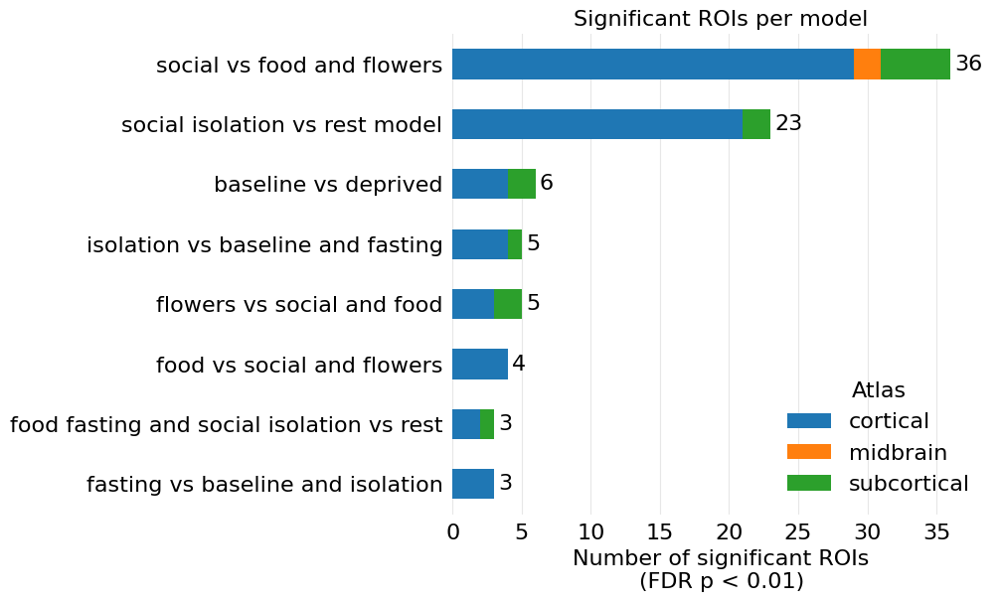

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

sig = model_summary.query("p_fdr < 0.01 and mean_rho > 0")

# 1) Number of significant ROIs per model (the value_counts from your screenshot)
# rows = model, columns = atlas, values = number of significant ROIs
counts = (
    sig.groupby(["model", "atlas"]).size().unstack(fill_value=0)
)
counts = counts.loc[counts.sum(axis=1).sort_values().index]  # largest bar on top
colors = {"cortical": "tab:blue", "midbrain": "tab:orange", "subcortical": "tab:green"}

ax = counts.plot(
    kind="barh", stacked=True, figsize=(10, 6),
    color=[colors[a] for a in counts.columns],
)

for i, total in enumerate(counts.sum(axis=1)):
    ax.text(total + 0.3, i, str(total), va="center")

ax.set_xlabel("Number of significant ROIs (FDR p < 0.01)")
ax.set_ylabel("")
ax.set_title("Significant ROIs per model")
ax.legend(title="atlas", frameon=False)

# remove the surrounding box
import seaborn as sns
sns.despine(left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# light vertical gridlines behind the bars, like the reference
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

# Readable, regular-weight text at the final printed size.
from textwrap import fill

labels = [str(model).replace("_", " ") for model in counts.index]
ax.set_yticks(range(len(counts)))
ax.set_yticklabels(labels, fontsize=16, fontweight="medium")

ax.tick_params(axis="x", labelsize=16, colors="black")
ax.set_xlabel("Number of significant ROIs\n(FDR p < 0.01)",
              fontsize=16, color="black", fontweight="medium")
ax.set_title("Significant ROIs per model", fontsize=16, fontweight="medium")
ax.legend(title="Atlas", frameon=False, fontsize=16, title_fontsize=16)
for text in ax.texts:
    text.set_fontsize(16)
    text.set_color("black")
    text.set_fontweight("medium")
ax.margins(x=0.08)

plt.tight_layout(pad=0.5)
# save as pdf
plt.savefig("signif_roi_atlases.pdf", bbox_inches="tight")   
plt.show()


In [34]:
model_summary.query('p_fdr < 0.01').query("roi == 'Lingual Gyrus'")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
144,cortical,Lingual Gyrus,baseline_vs_deprived,32,0.324551,0.232467,0.416806,1.017645e-07,0.000002
145,cortical,Lingual Gyrus,fasting_vs_baseline_and_isolation,32,0.252354,0.152745,0.357474,4.716826e-05,0.000382
146,cortical,Lingual Gyrus,flowers_vs_social_and_food,32,-0.076876,-0.107459,-0.044956,4.256614e-05,0.000360
150,cortical,Lingual Gyrus,isolation_vs_baseline_and_fasting,32,0.302156,0.210068,0.396580,5.899696e-07,0.000009


In [35]:
model_summary.query('p_fdr < 0.01').query("roi == 'Occipital Fusiform Gyrus'")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
180,cortical,Occipital Fusiform Gyrus,baseline_vs_deprived,32,0.239319,0.157090,0.321041,3.472983e-06,4.333336e-05
181,cortical,Occipital Fusiform Gyrus,fasting_vs_baseline_and_isolation,32,0.252187,0.149407,0.358978,6.757297e-05,5.225009e-04
182,cortical,Occipital Fusiform Gyrus,flowers_vs_social_and_food,32,-0.091249,-0.122835,-0.055986,1.029126e-05,1.107824e-04
186,cortical,Occipital Fusiform Gyrus,isolation_vs_baseline_and_fasting,32,0.348449,0.264550,0.433013,3.811206e-09,1.046176e-07
187,cortical,Occipital Fusiform Gyrus,social_isolation_vs_rest_model,32,0.092859,0.044415,0.140293,8.850774e-04,5.459634e-03
188,cortical,Occipital Fusiform Gyrus,social_vs_food_and_flowers,32,0.153585,0.073199,0.242160,1.523301e-03,8.992389e-03


In [36]:
model_summary.query('p_fdr < 0.01').query('model == "food_fasting_and_social_isolation_vs_rest"')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
93,cortical,"Inferior Frontal Gyrus, pars triangularis",food_fasting_and_social_isolation_vs_rest,32,0.134726,0.074220,0.198319,0.000214,0.001549
156,cortical,Middle Frontal Gyrus,food_fasting_and_social_isolation_vs_rest,32,0.156324,0.088104,0.226944,0.000154,0.001129
498,subcortical,Cerebral White Matter,food_fasting_and_social_isolation_vs_rest,32,0.059650,0.027082,0.092903,0.001489,0.008884


In [37]:
model_summary.query('p_fdr < 0.01').query('model == "food_vs_social_and_flowers"')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
41,cortical,Cuneal Cortex,food_vs_social_and_flowers,32,-0.091081,-0.121999,-0.057323,6.604734e-06,7.399998e-05
50,cortical,Frontal Medial Cortex,food_vs_social_and_flowers,32,-0.082057,-0.108295,-0.053813,2.566367e-06,3.354608e-05
104,cortical,Insular Cortex,food_vs_social_and_flowers,32,0.272576,0.204390,0.343444,1.661487e-08,3.965898e-07
113,cortical,Intracalcarine Cortex,food_vs_social_and_flowers,32,-0.100273,-0.137040,-0.059161,2.489414e-05,2.316421e-04
140,cortical,"Lateral Occipital Cortex, superior division",food_vs_social_and_flowers,32,0.148237,0.093087,0.202719,1.191699e-05,1.258159e-04
266,cortical,Subcallosal Cortex,food_vs_social_and_flowers,20,-0.093856,-0.134232,-0.053746,3.126998e-04,2.145902e-03
311,cortical,Supracalcarine Cortex,food_vs_social_and_flowers,32,-0.069690,-0.102111,-0.036600,2.776853e-04,1.940743e-03
320,cortical,"Supramarginal Gyrus, anterior division",food_vs_social_and_flowers,32,0.196870,0.134366,0.259544,1.115100e-06,1.530475e-05
338,cortical,Temporal Occipital Fusiform Cortex,food_vs_social_and_flowers,32,0.068687,0.039608,0.098936,1.202351e-04,8.920142e-04


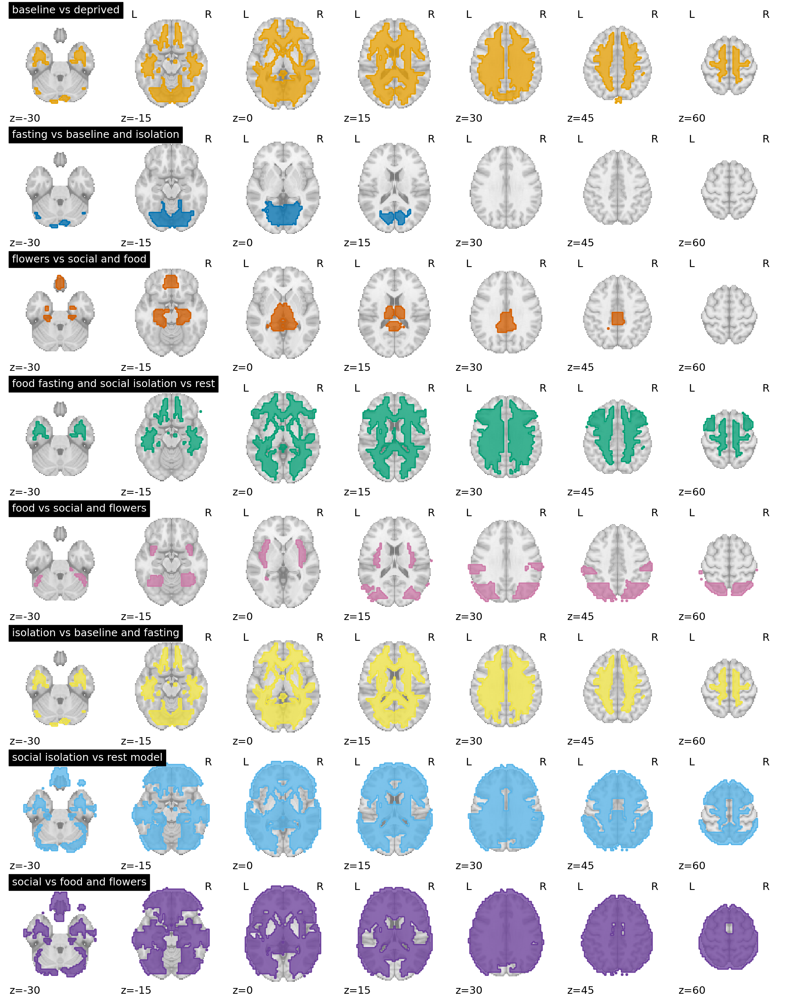

In [83]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import nibabel as nib
import numpy as np
from nilearn import plotting
from nilearn.image import resample_to_img


mask_dir = Path("/local/anpa/probing_rsa_fasting_social_isolation/masks")  

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------


p_threshold = 0.01

# These coordinates are in millimeters and assume MNI space.
# Adjust them if your masks and anatomical background are
# in a different space.
slice_positions = [-30, -15, 0, 15, 30, 45, 60]

# Set to a matching anatomical NIfTI image if not using MNI.
# None uses Nilearn's default MNI template.
background_image = None

# ------------------------------------------------------------
# SELECT SIGNIFICANT RESULTS
# ------------------------------------------------------------

#significant = model_summary.query('p_fdr < 0.01 & mean_rho > 0').sort_values("p_fdr")
significant = (
    model_summary.loc[
        (model_summary["p_fdr"] < p_threshold) & (model_summary["mean_rho"] > 0),
        ["roi", "model"]
    ]
    .dropna()
    .drop_duplicates()
)

if significant.empty:
    raise ValueError("No significant ROI–model pairs found.")

models = sorted(significant["model"].unique())
rois = sorted(significant["roi"].unique())

# ------------------------------------------------------------
# FIND ROI MASKS
# ------------------------------------------------------------

def mask_name(path):
    if path.name.endswith(".nii.gz"):
        return path.name[:-7]
    if path.name.endswith(".nii"):
        return path.name[:-4]
    return None


mask_files = {}

for path in mask_dir.iterdir():
    name = mask_name(path)
    if name is not None:
        if name in mask_files:
            raise ValueError(f"Multiple masks found for: {name}")
        mask_files[name] = path

missing = [roi for roi in rois if roi not in mask_files]

if missing:
    raise FileNotFoundError(
        "Masks not found for:\n" + "\n".join(missing)
    )

# ------------------------------------------------------------
# LOAD MASKS ON A COMMON GRID
# ------------------------------------------------------------

#reference = nib.load(str(mask_files[rois[0]]))
from nilearn import datasets
reference = datasets.load_mni152_template()

if len(reference.shape) != 3:
    raise ValueError("Expected 3D ROI masks.")

roi_masks = {}

for roi in rois:
    mask = nib.load(str(mask_files[roi]))

    if len(mask.shape) != 3:
        raise ValueError(f"Mask for {roi} is not 3D.")

    if (
        mask.shape != reference.shape
        or not np.allclose(mask.affine, reference.affine)
    ):
        mask = resample_to_img(
            mask,
            reference,
            interpolation="nearest",
        )

    # Assumes binary masks with values 0 and 1.
    roi_masks[roi] = np.asarray(mask.dataobj) > 0.5

# ------------------------------------------------------------
# PLOT ONE ROW PER MODEL
# ------------------------------------------------------------
# ------------------------------------------------------------
# PLOT ONE ROW PER MODEL — MANUALLY POSITIONED
# ------------------------------------------------------------

from matplotlib.colors import ListedColormap

if len(models) > 20:
    raise ValueError("More than 20 models: choose a larger color palette.")

#colors = plt.get_cmap("tab20").colors
# Saturated, distinct colors (Okabe-Ito style + extras), up to 12 models
colors = [
    "#E69F00",  # orange
    "#0072B2",  # blue
    "#D55E00",  # vermilion
    "#009E73",  # green
    "#CC79A7",  # pink
    "#F0E442",  # yellow
    "#56B4E9",  # sky blue
    "#6A3D9A",  # purple
    "#B15928",  # brown
    "#1B1B1B",  # near-black
    "#E31A1C",  # red
    "#33A02C",  # dark green
]
if len(models) > len(colors):
    raise ValueError("More models than colors; extend the list.")
n_models = len(models)

fig = plt.figure(figsize=(20, 3 * n_models))

# Leave a small gap between rows.
row_height = 1 / n_models
gap = 0.02 * row_height

for i, model in enumerate(models):
    color = colors[i]

    model_rois = significant.loc[
        significant["model"] == model, "roi"
    ].unique()

    combined = np.zeros(reference.shape, dtype=np.uint8)

    for roi in model_rois:
        combined[roi_masks[roi]] = 1

    if not combined.any():
        print(f"Warning: no mask voxels found for {model}")
        continue

    combined_img = nib.Nifti1Image(combined, reference.affine)

    # Place each row before Nilearn creates its slice axes.
    bottom = 1 - (i + 1) * row_height + gap
    ax = fig.add_axes([
        0.03,                  # left
        bottom,                # bottom
        0.94,                  # width
        row_height - 2 * gap,  # height
    ])

    plot_kwargs = {
        "display_mode": "z",
        "cut_coords": slice_positions,
        "figure": fig,
        "axes": ax,
        # "title": model.replace("_", " "),
        "draw_cross": False,
        "black_bg": False,
        "colorbar": False
    }

    # Omit anat_img for Nilearn's default MNI template.
    if background_image is not None:
        plot_kwargs["anat_img"] = background_image

    display = plotting.plot_anat(**plot_kwargs)

    display.add_overlay(
            combined_img,
            cmap=ListedColormap([color]),
            threshold=0.5,
            vmin=0,
            vmax=1,
            transparency=0.75,   # was 0.35
            interpolation="nearest",
        )
    display.title(model.replace("_", " "), size=18)   # bigger black-box title
    display.annotate(size=18)   

    display.add_contours(
        combined_img,
        levels=[0.5],
        colors=[color],
        linewidths=2.0,      # was 1.2
    )


plt.show()

In [44]:
# def plot_group_average(roi_name):
#     mats = rdms["rdms"][:, list(rdms["rois"]).index(roi_name)]
#     if mats.size == 0:
#         print(f"No subjects available for {roi_name}")
#         return

#     stacked = np.stack(mats, axis=0)
#     mean_rdm = np.mean(stacked, axis=0)  # Across-subject mean
#     n_subjects = stacked.shape[0]
#     sample_sd = np.std(stacked, axis=0, ddof=1)
#     sem_rdm = sample_sd / np.sqrt(n_subjects)

#     labels = [
#         "food_baseline", "social_baseline", "flowers_baseline",
#         "food_fasting", "social_fasting", "flowers_fasting",
#         "food_isolation", "social_isolation", "flowers_isolation",
#     ]

#     fig, axes = plt.subplots(1, 2, figsize=(17, 7), constrained_layout=True)

#     for ax, matrix, title, colorbar_label in [
#         (axes[0], mean_rdm, f"Group mean | {roi_name}", "Mean crossnobis distance"),
#         #(axes[1], std_rdm, f"Standard deviation | {roi_name}", "SD of crossnobis distance"),
#         (axes[1], sem_rdm, f"Standard error of the mean | {roi_name}", "SEM of crossnobis distance"),
#     ]:
#         image = ax.imshow(matrix, cmap="viridis", interpolation="nearest")
#         ax.set_title(title)
#         ax.set_xticks(range(len(labels)), labels=labels, rotation=90)
#         ax.set_yticks(range(len(labels)), labels=labels)

#         for row in range(matrix.shape[0]):
#             for col in range(matrix.shape[1]):
#                 value = matrix[row, col]
#                 rgba = image.cmap(image.norm(value))
#                 brightness = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
#                 ax.text(
#                     col, row, f"{value:.3f}",
#                     ha="center", va="center",
#                     color="black" if brightness > 0.55 else "white",
#                     fontsize=7,
#                 )

#         fig.colorbar(image, ax=ax, label=colorbar_label)

#     plt.show()
    

# for roi_name in list(rdms["rois"]):
#     plot_group_average(roi_name)

food, baseline: food_baseline
food, fasting: food_fasting
social, baseline: social_baseline
social, isolation: social_isolation
flowers, baseline: flowers_baseline
flowers, fasting: flowers_fasting
Skipping Frontal Pole.nii: insufficient complete pairs.


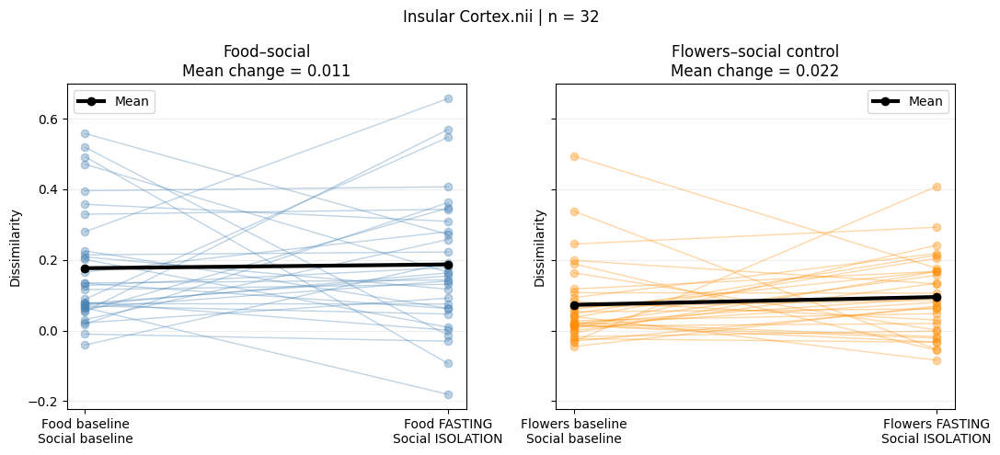

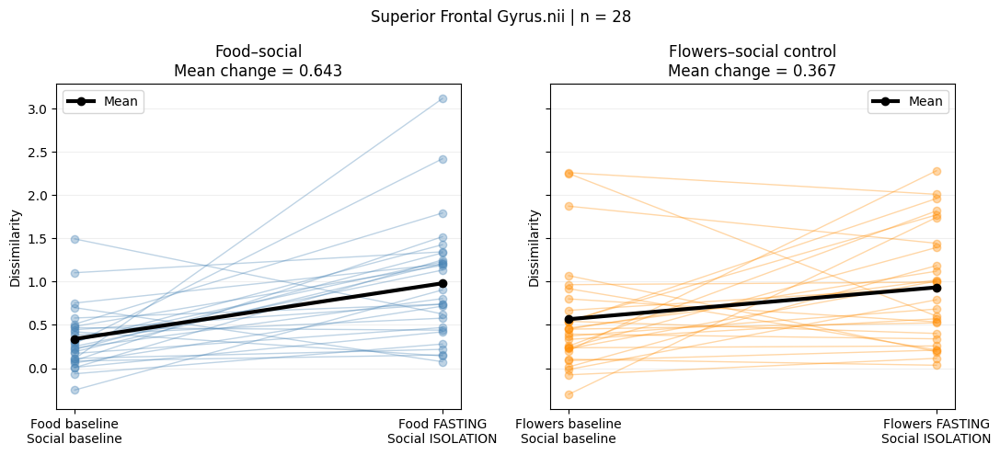

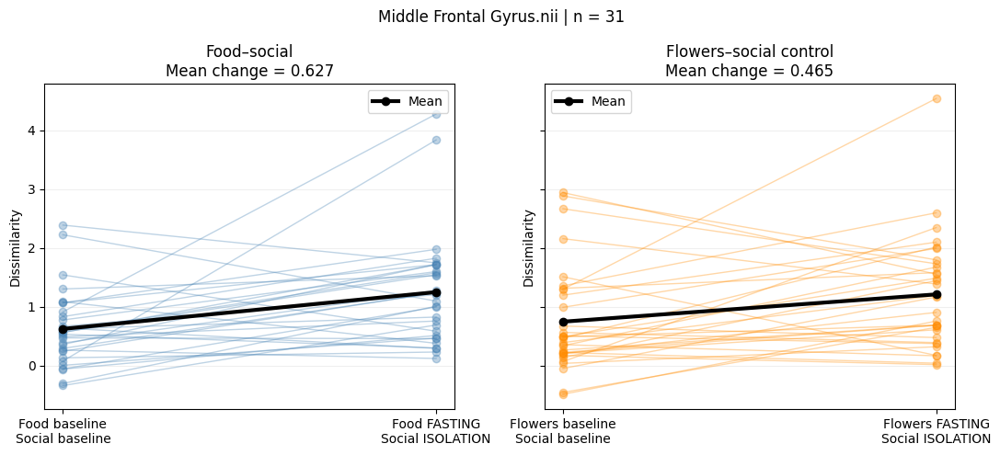

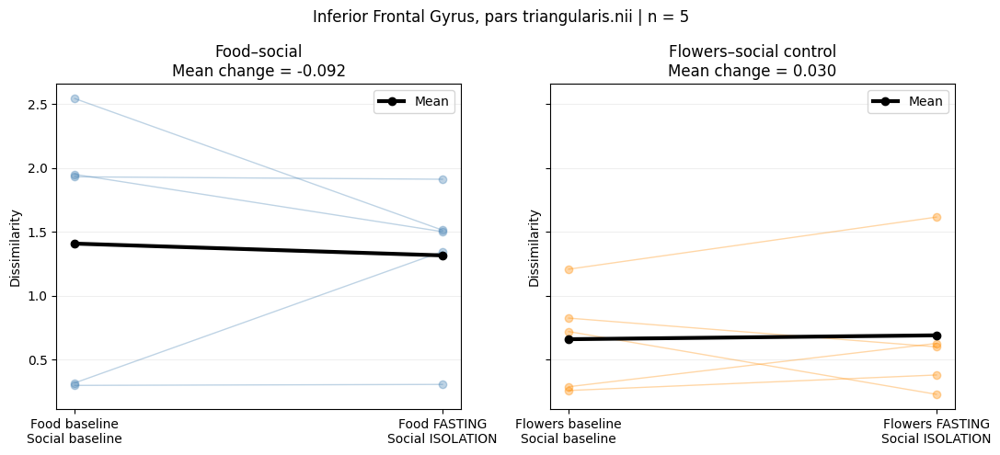

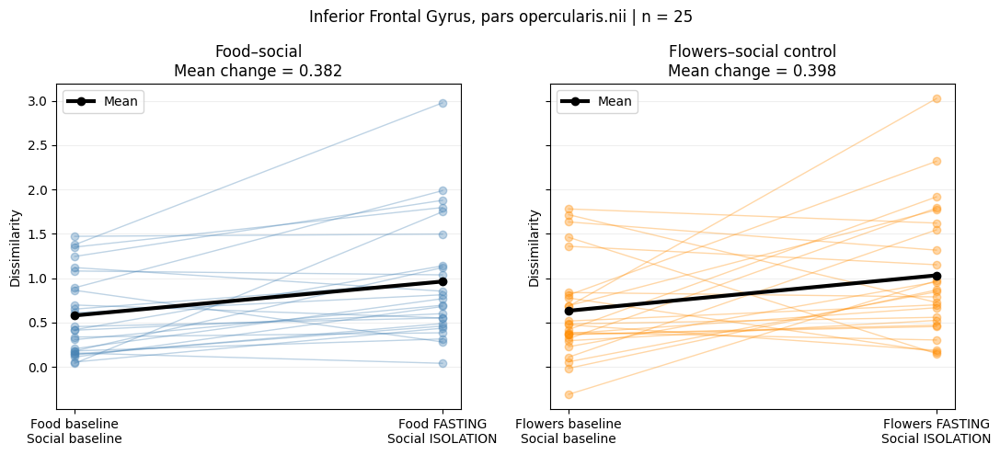

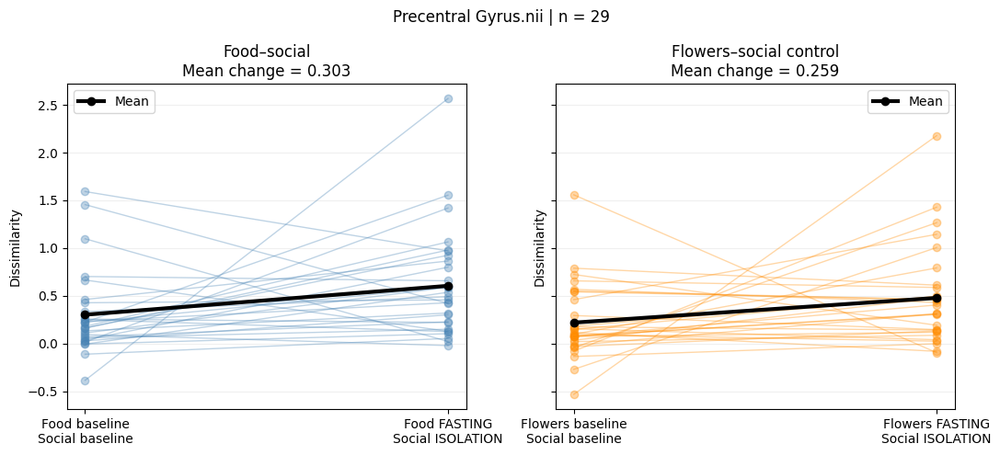

Skipping Temporal Pole.nii: insufficient complete pairs.


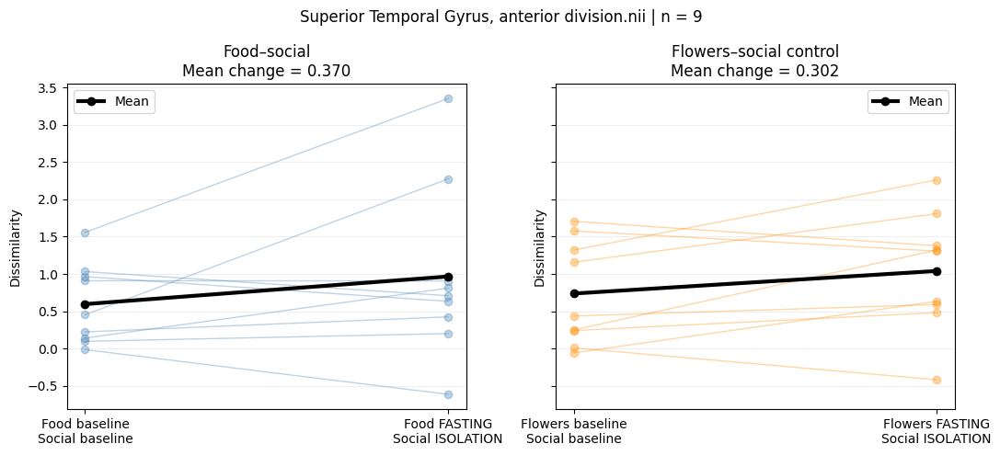

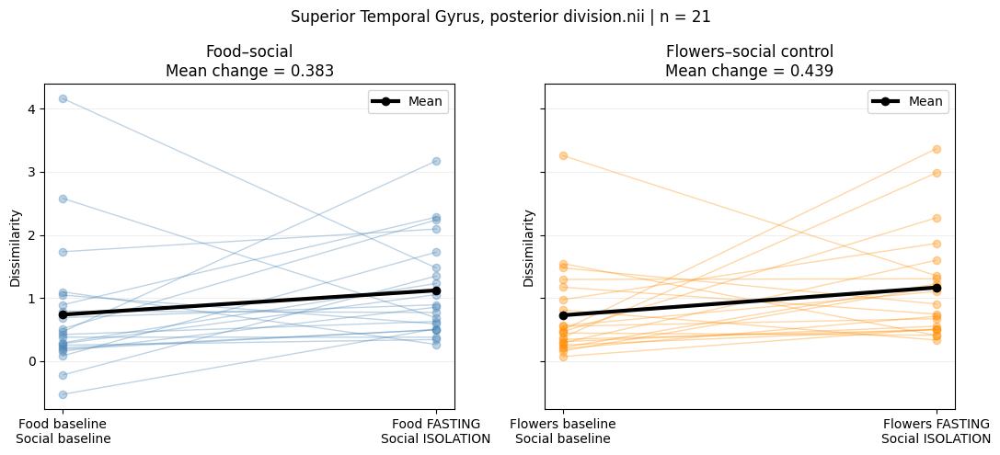

Skipping Middle Temporal Gyrus, anterior division.nii: insufficient complete pairs.
Skipping Middle Temporal Gyrus, posterior division.nii: insufficient complete pairs.
Skipping Middle Temporal Gyrus, temporooccipital part.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, anterior division.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, posterior division.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, temporooccipital part.nii: insufficient complete pairs.


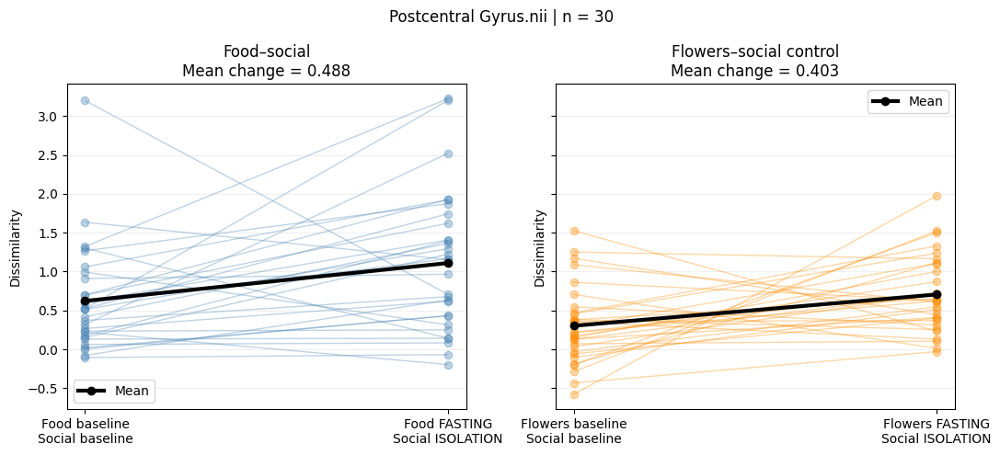

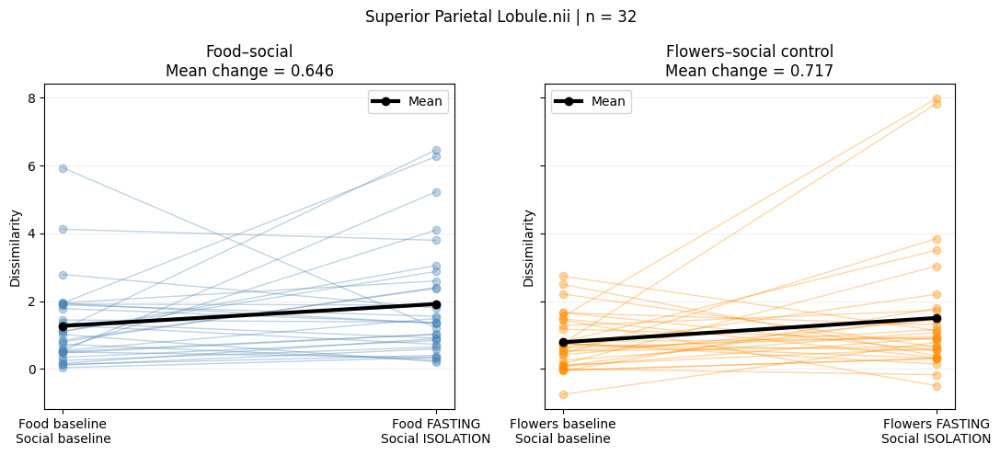

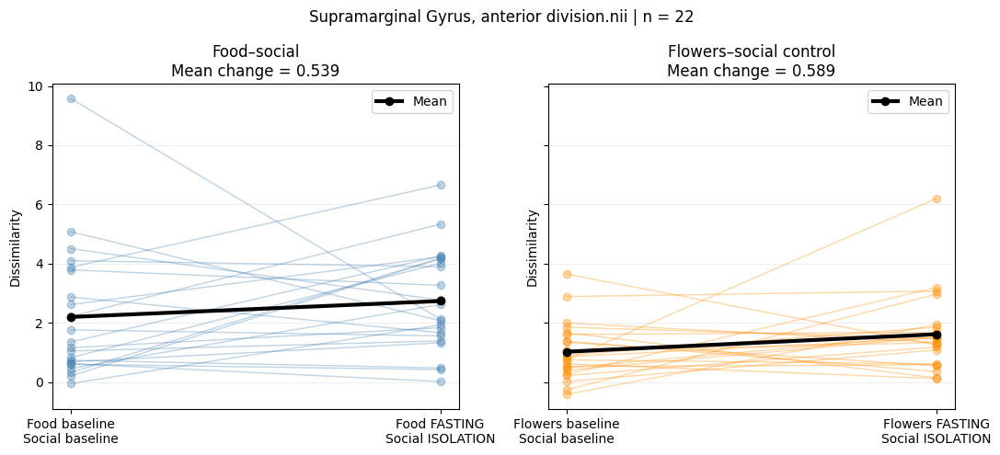

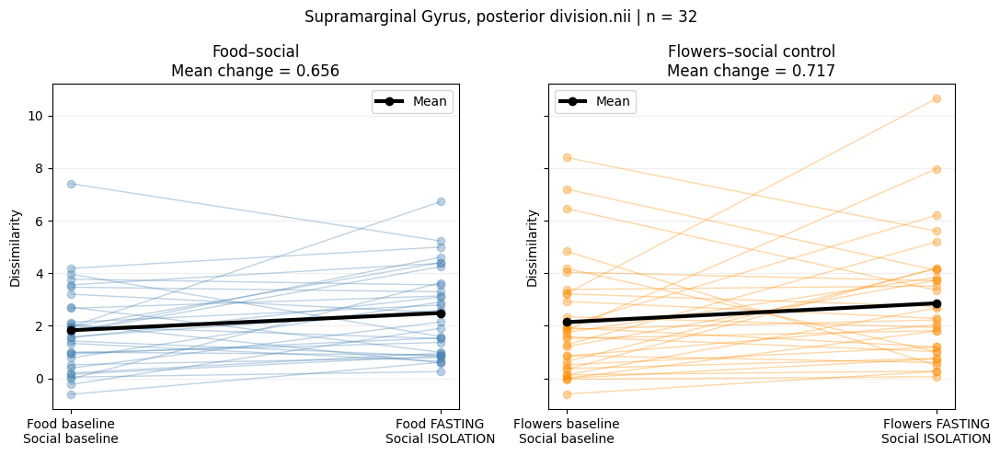

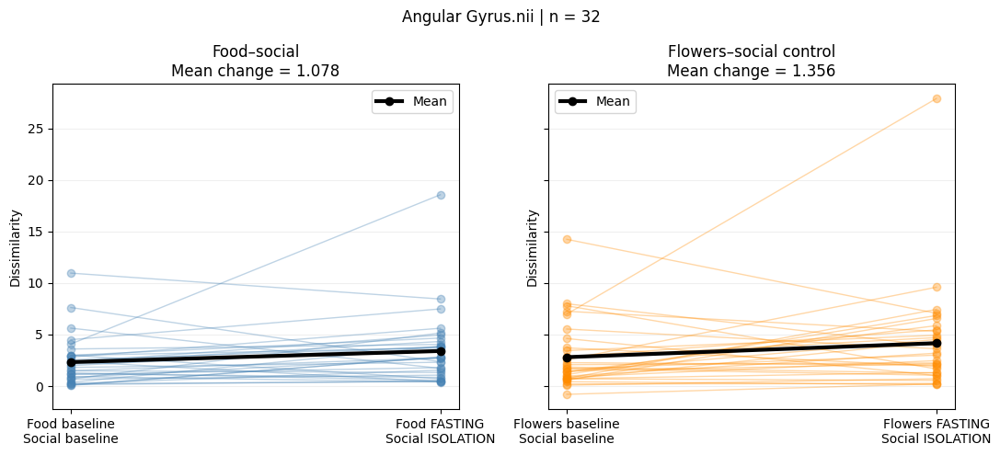

Skipping Lateral Occipital Cortex, superior division.nii: insufficient complete pairs.
Skipping Lateral Occipital Cortex, inferior division.nii: insufficient complete pairs.


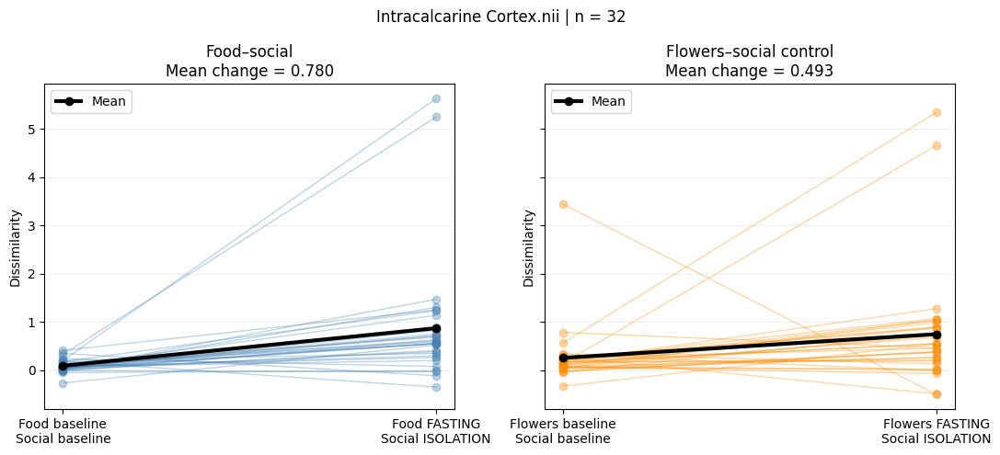

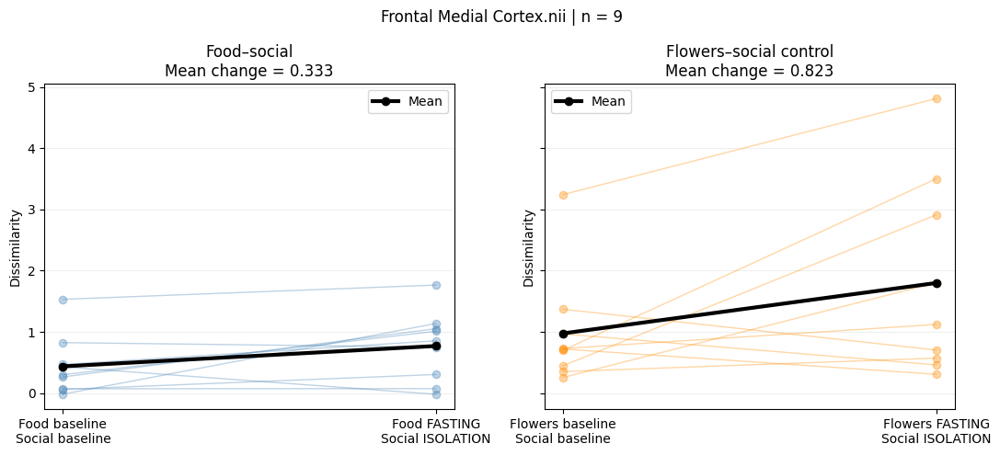

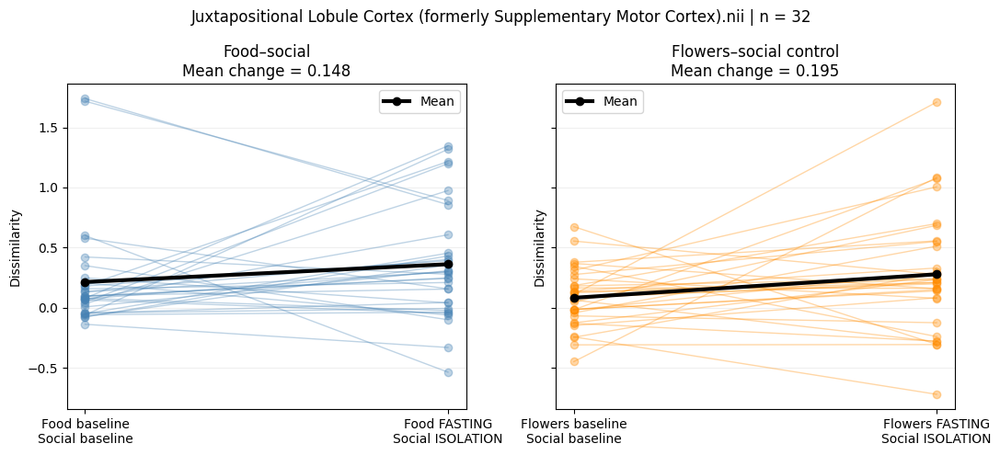

Skipping Subcallosal Cortex.nii: insufficient complete pairs.


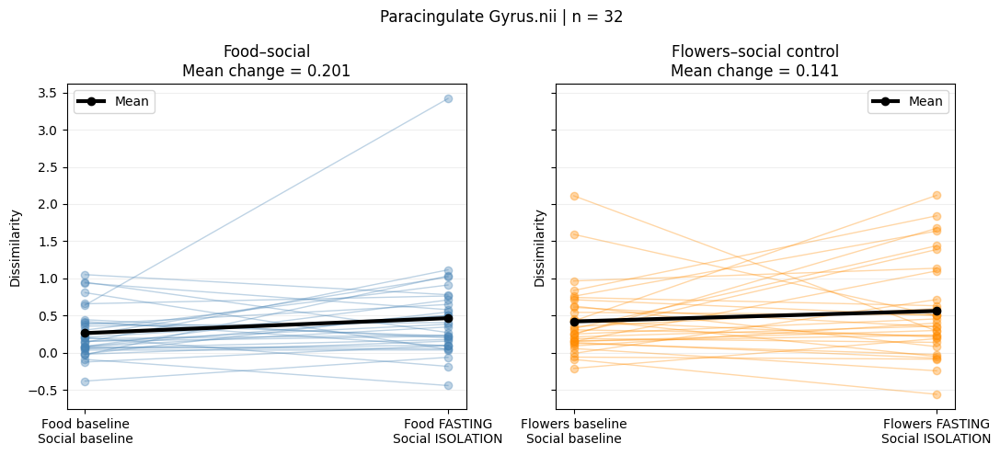

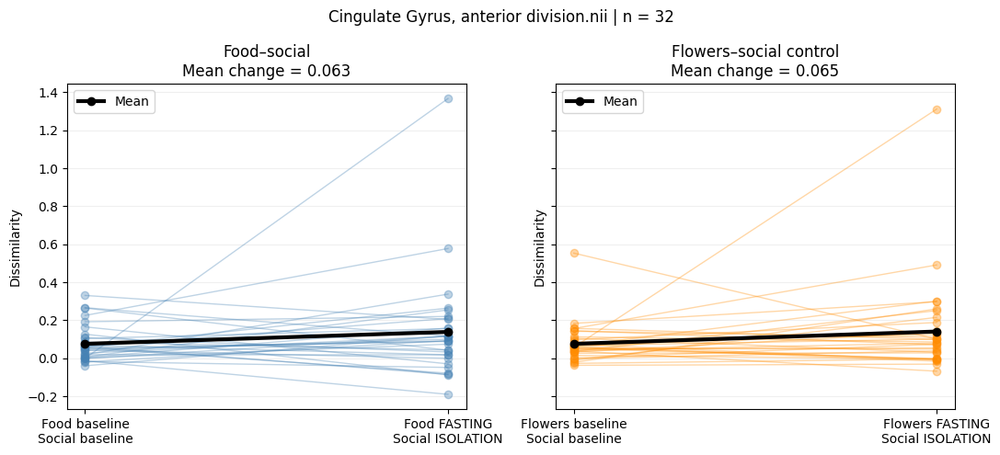

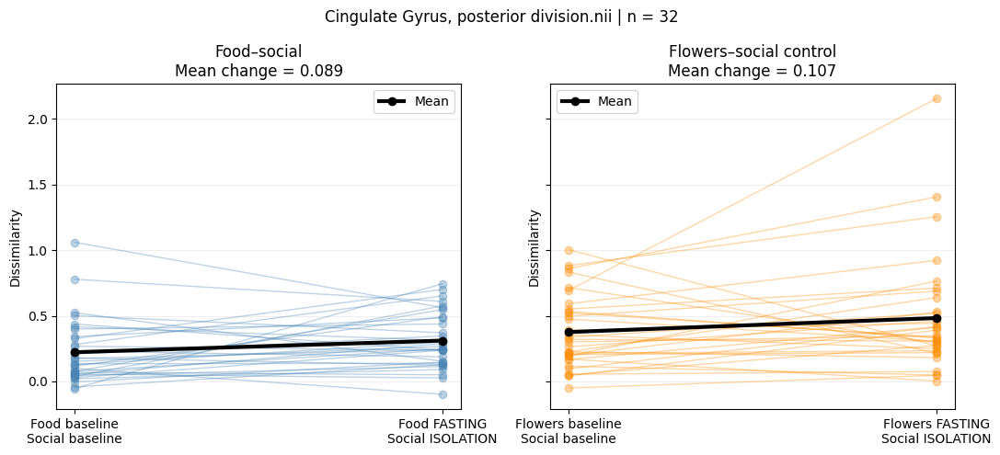

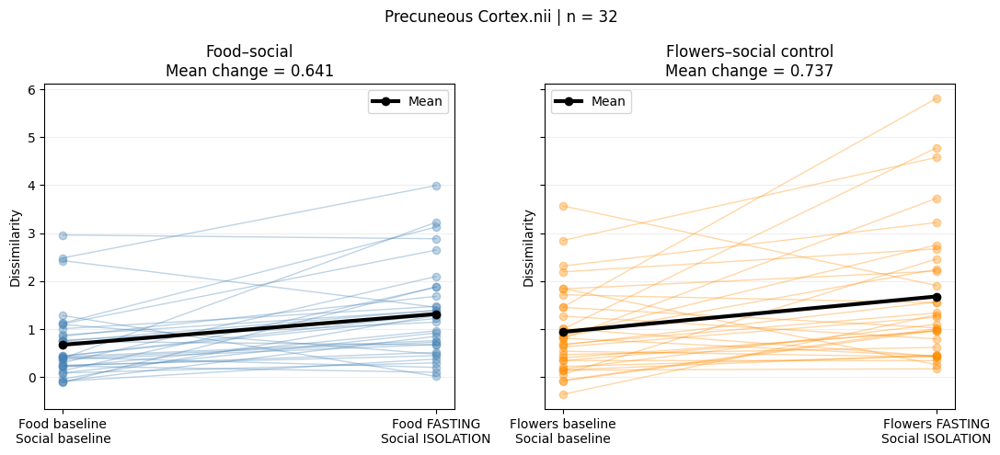

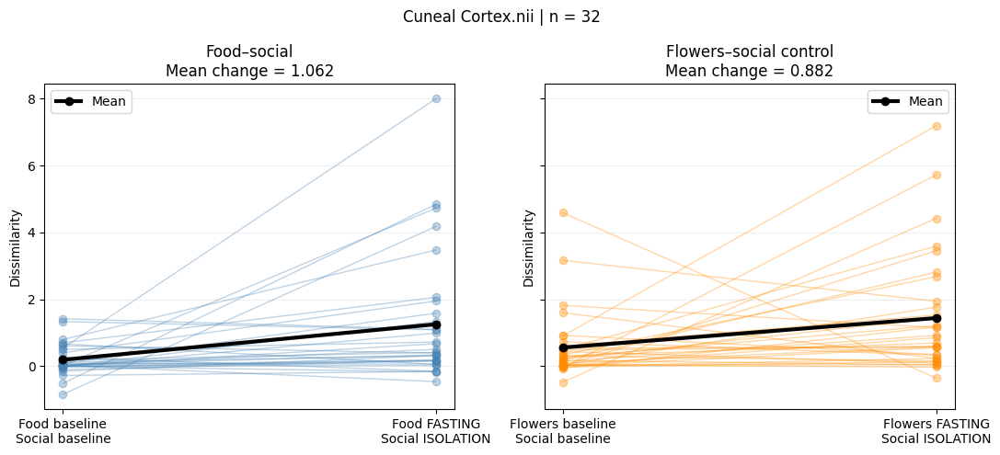

Skipping Frontal Orbital Cortex.nii: insufficient complete pairs.
Skipping Parahippocampal Gyrus, anterior division.nii: insufficient complete pairs.


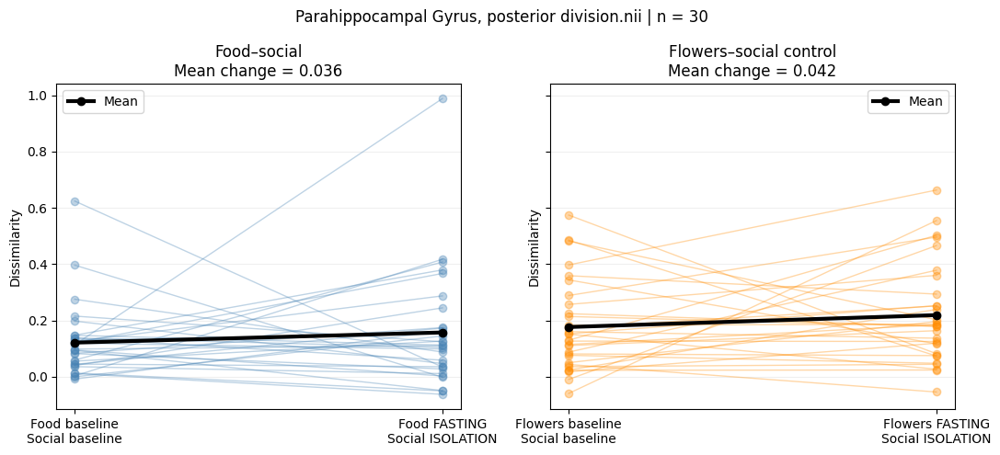

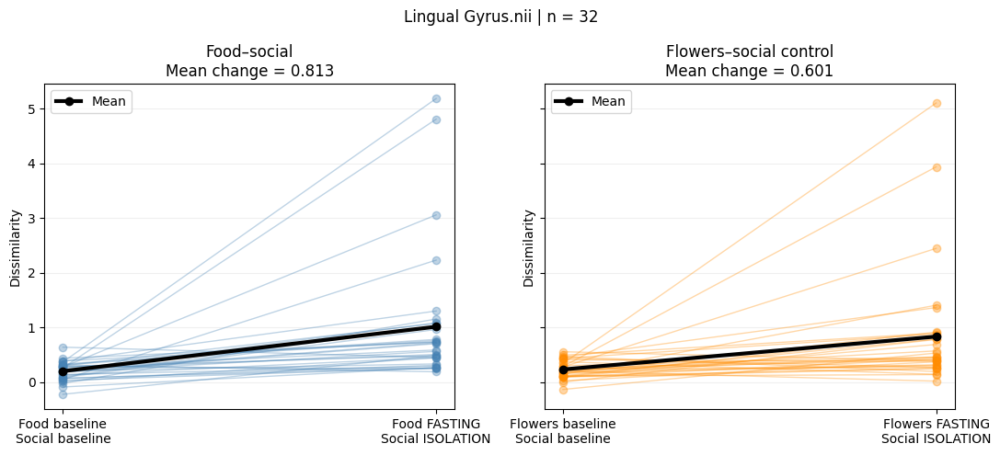

Skipping Temporal Fusiform Cortex, anterior division.nii: insufficient complete pairs.
Skipping Temporal Fusiform Cortex, posterior division.nii: insufficient complete pairs.


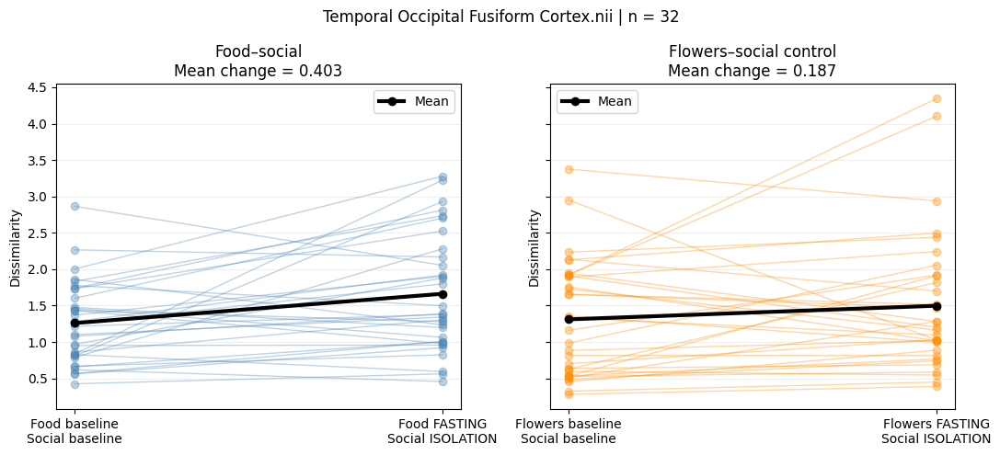

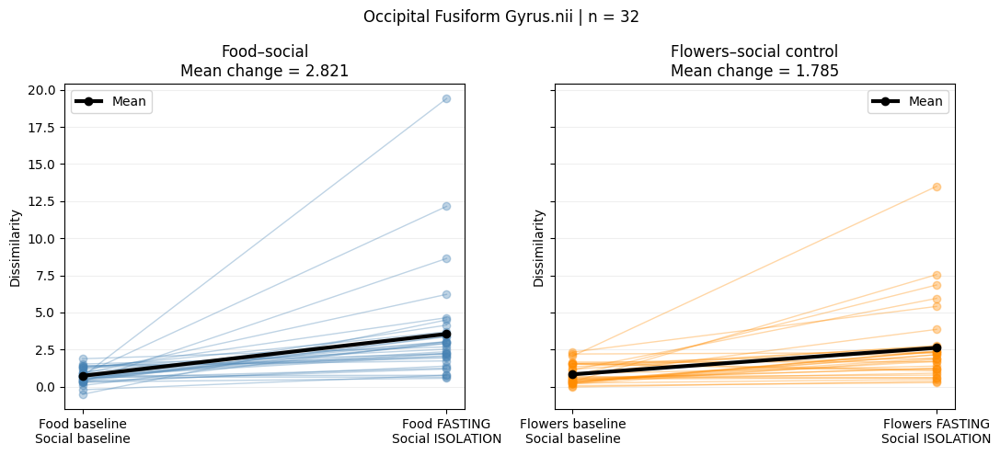

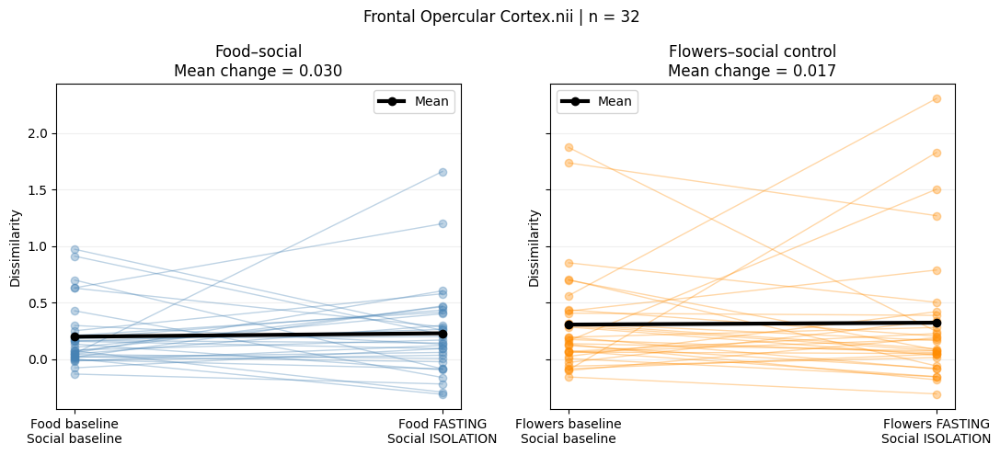

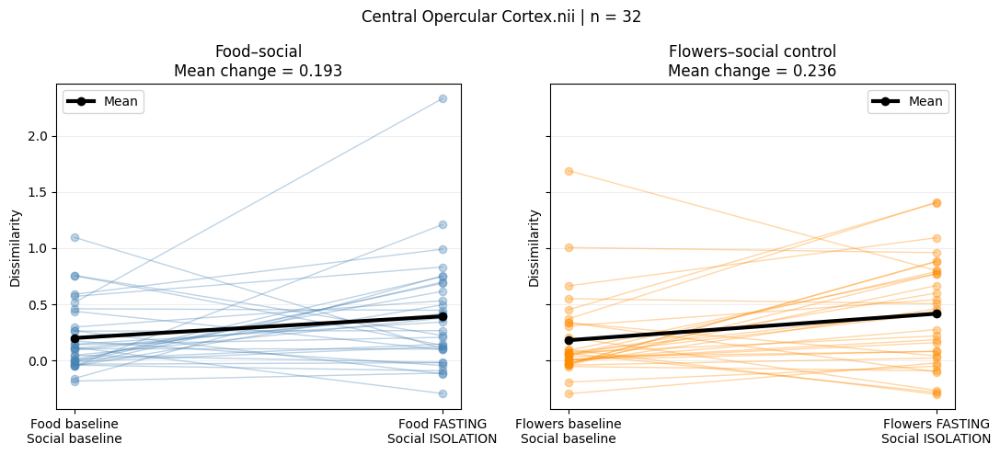

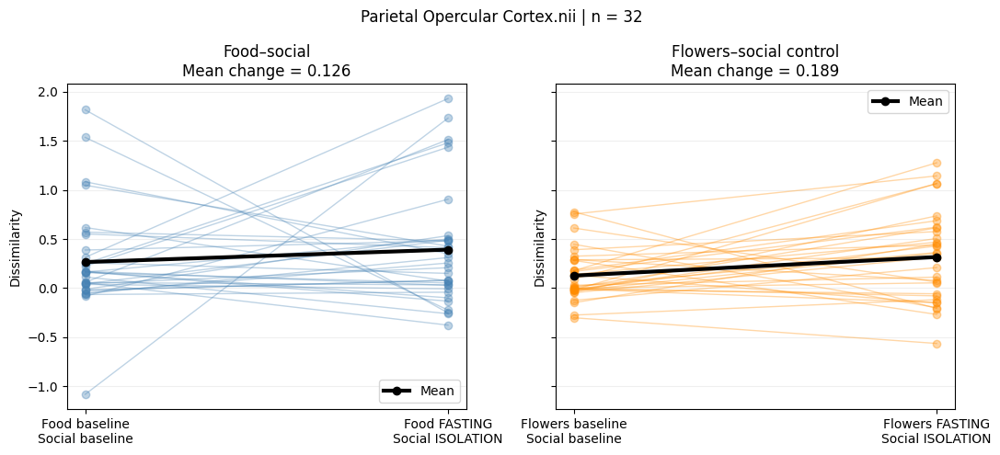

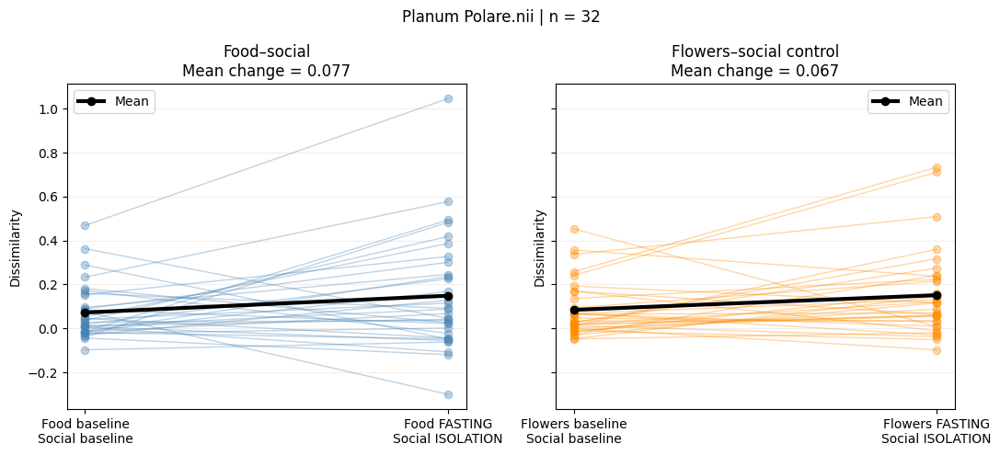

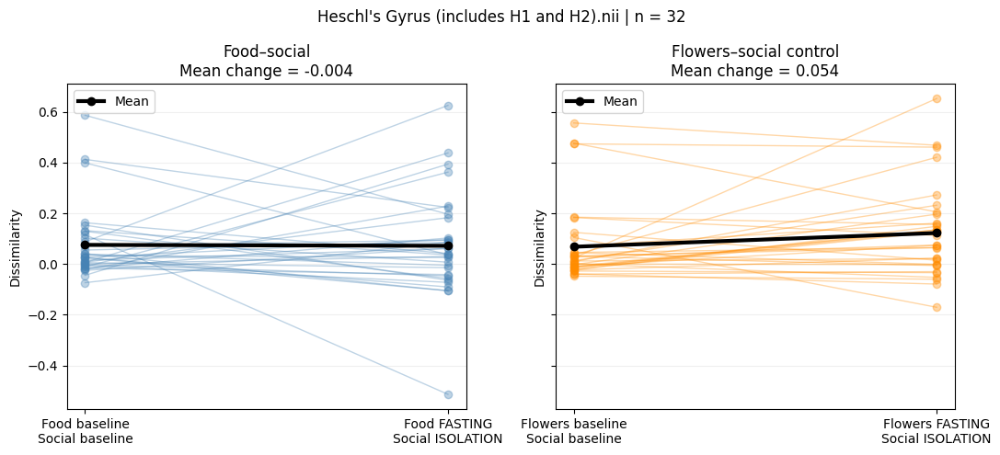

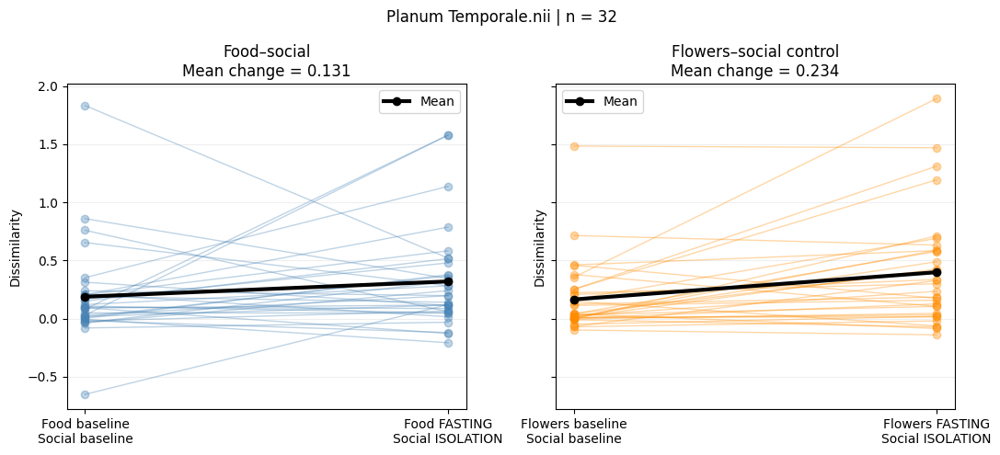

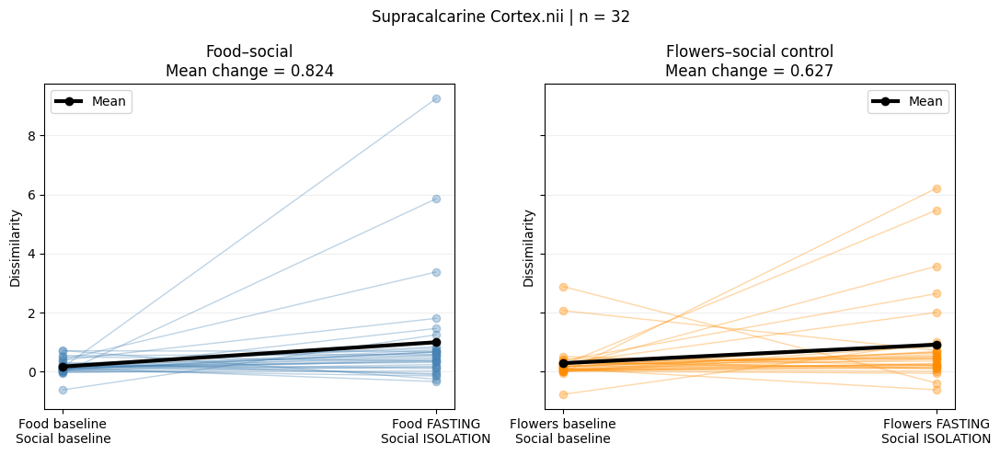

Skipping Occipital Pole.nii: insufficient complete pairs.


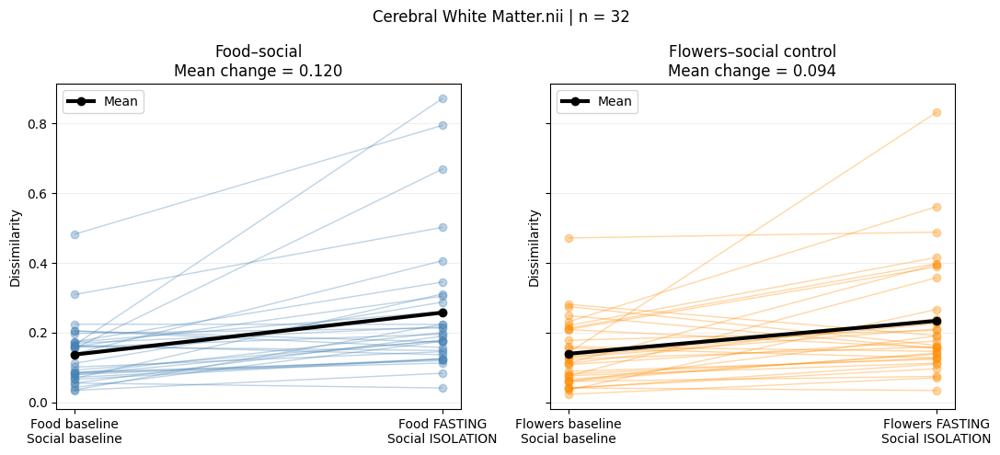

Skipping Cerebral Cortex.nii: insufficient complete pairs.


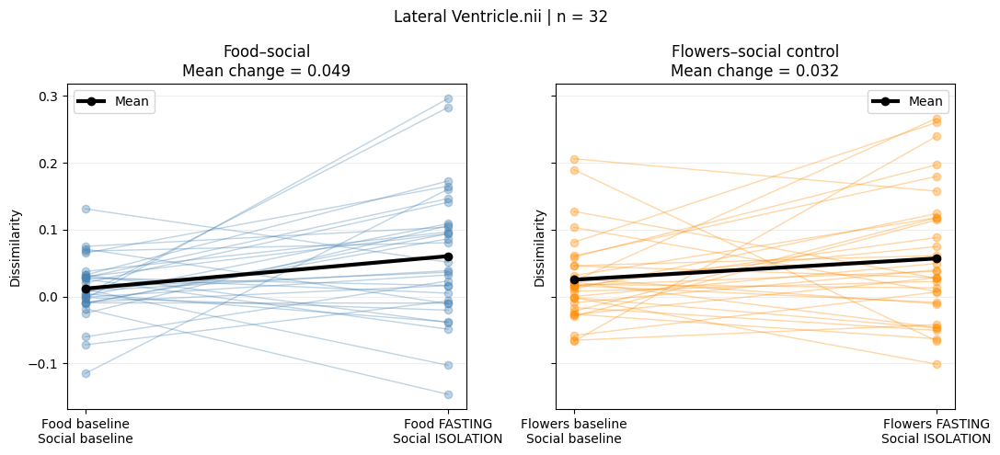

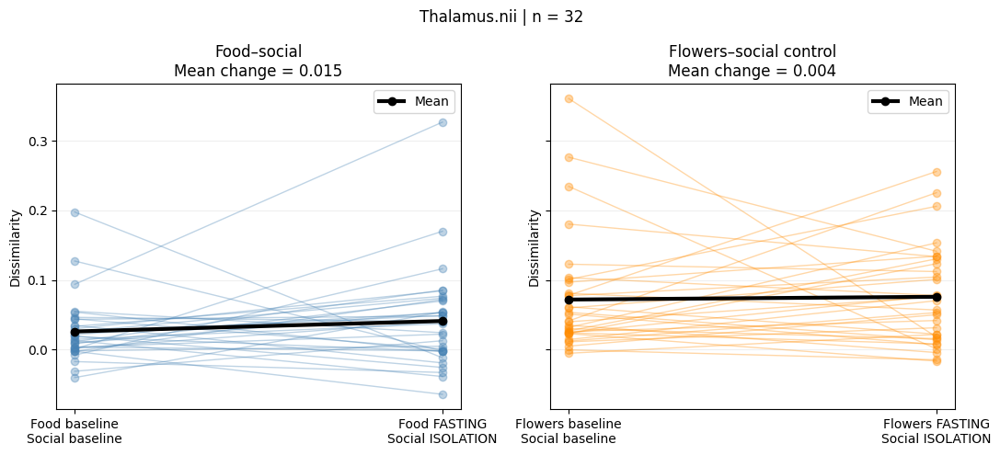

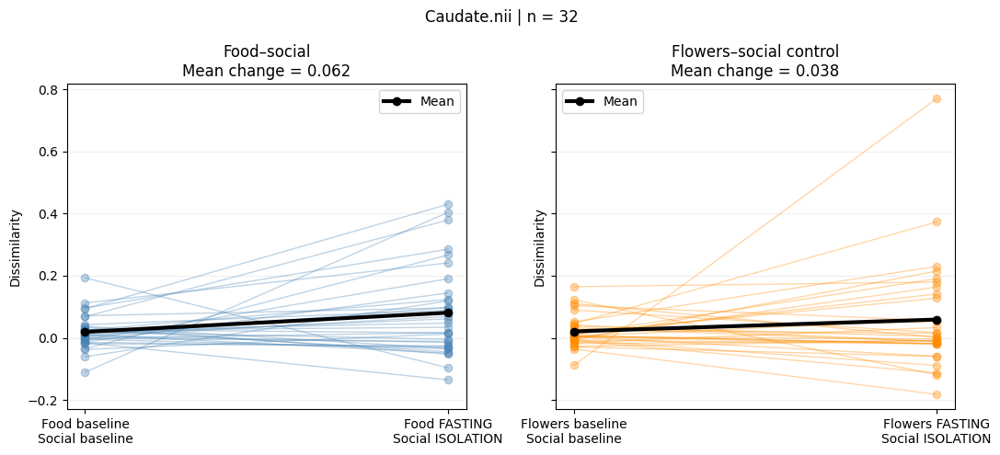

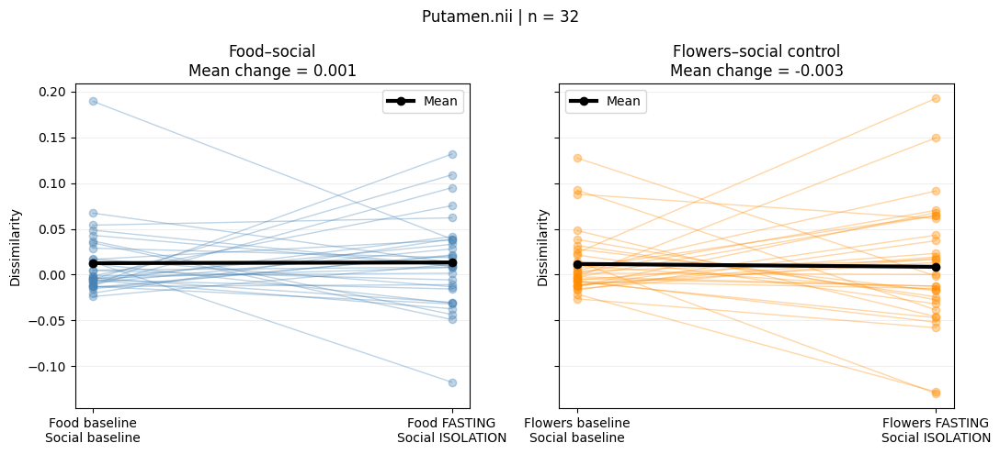

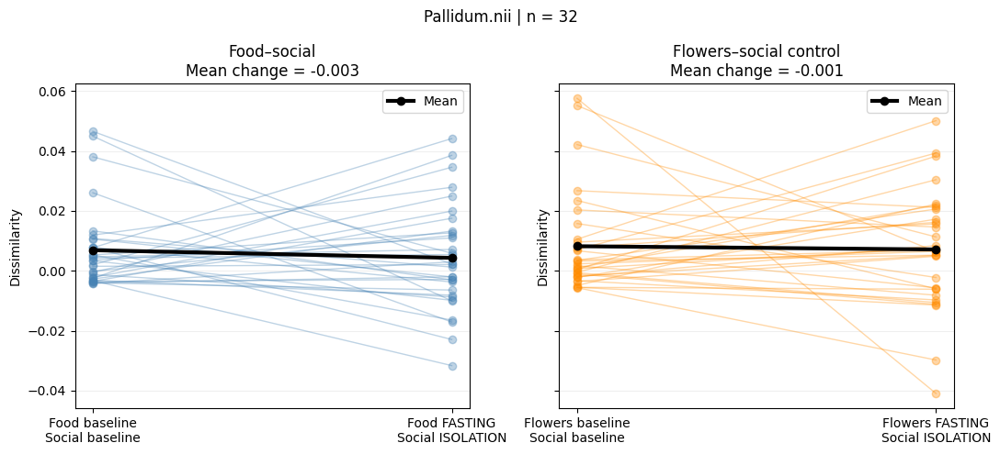

Skipping Brain-Stem.nii: insufficient complete pairs.


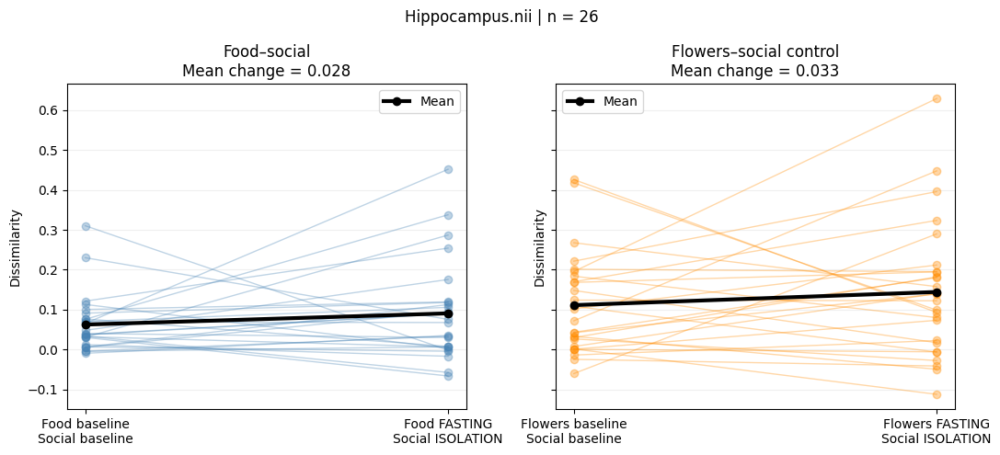

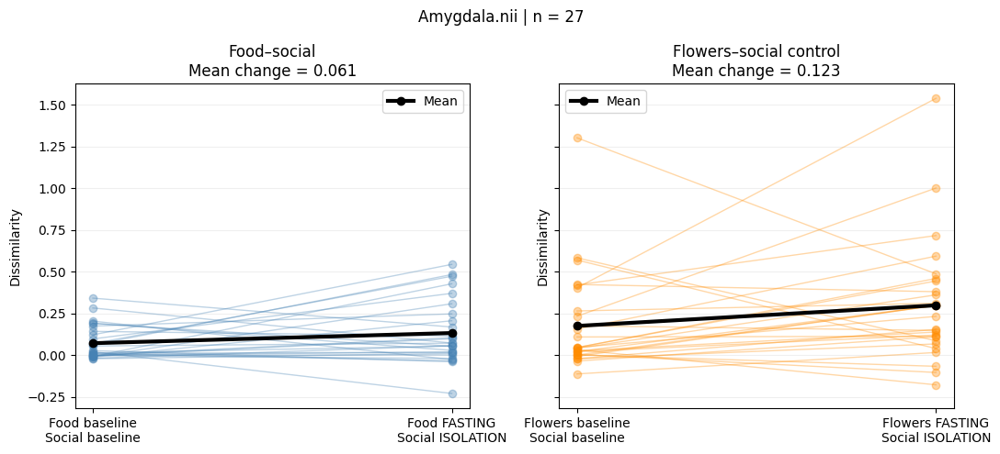

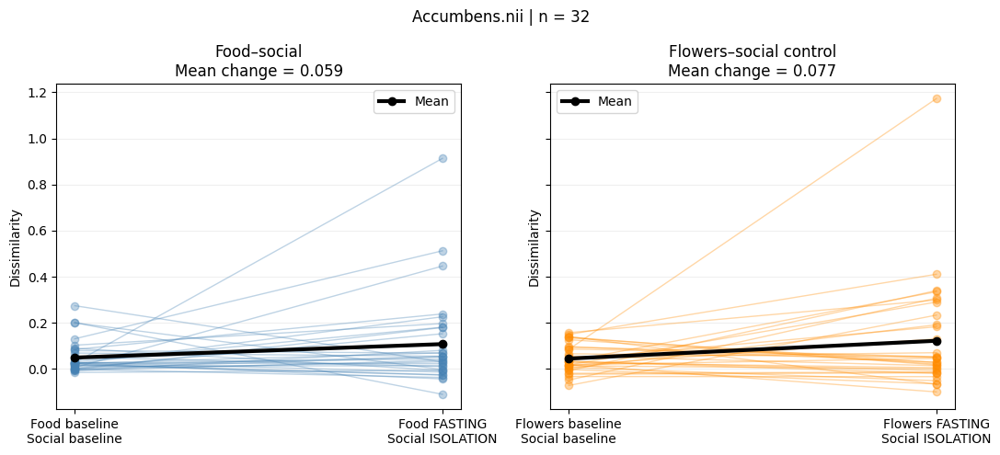

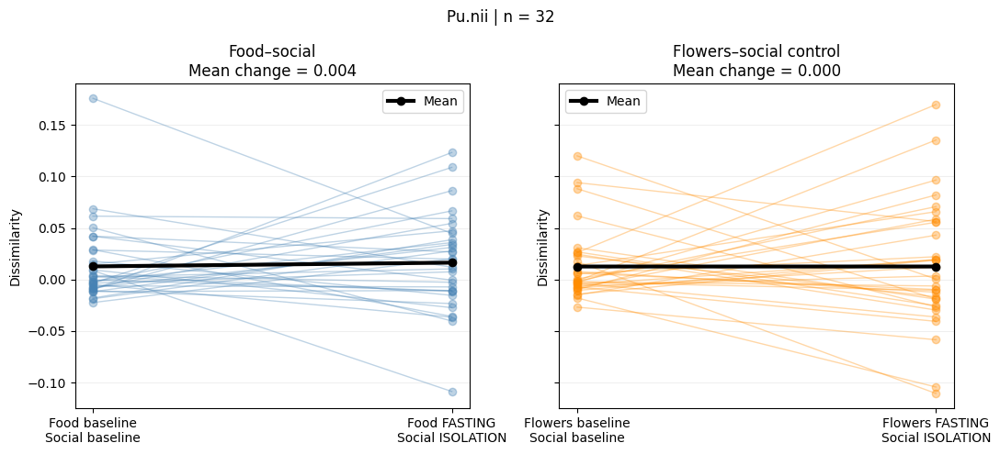

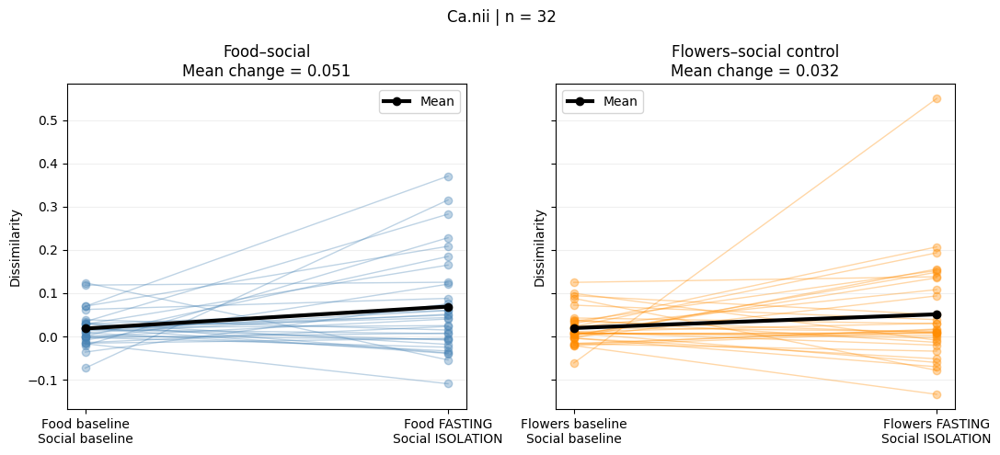

...

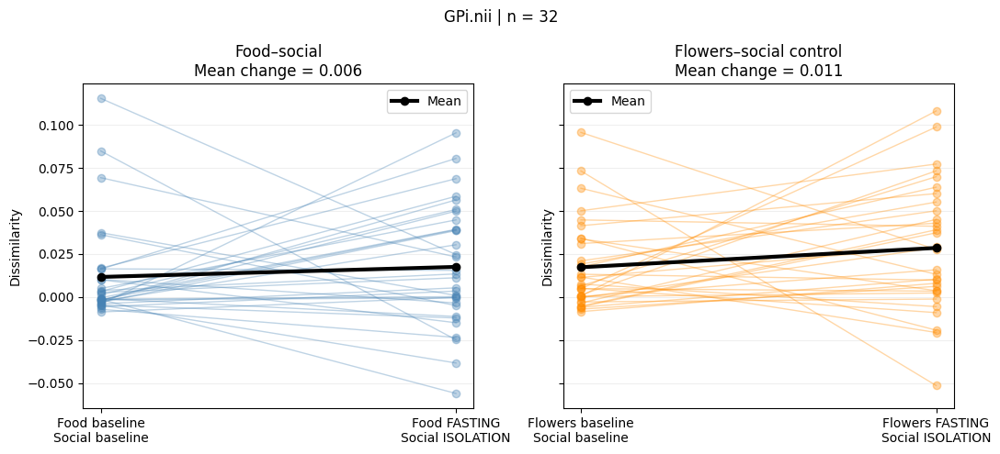

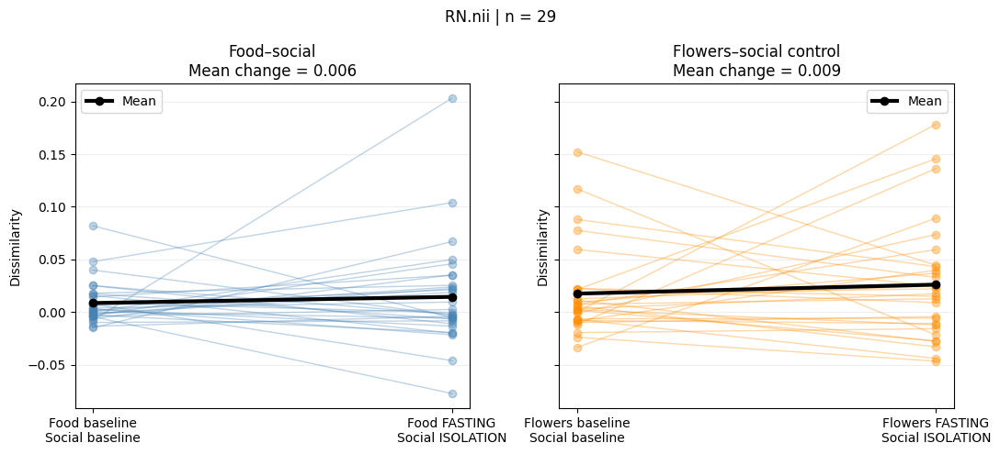

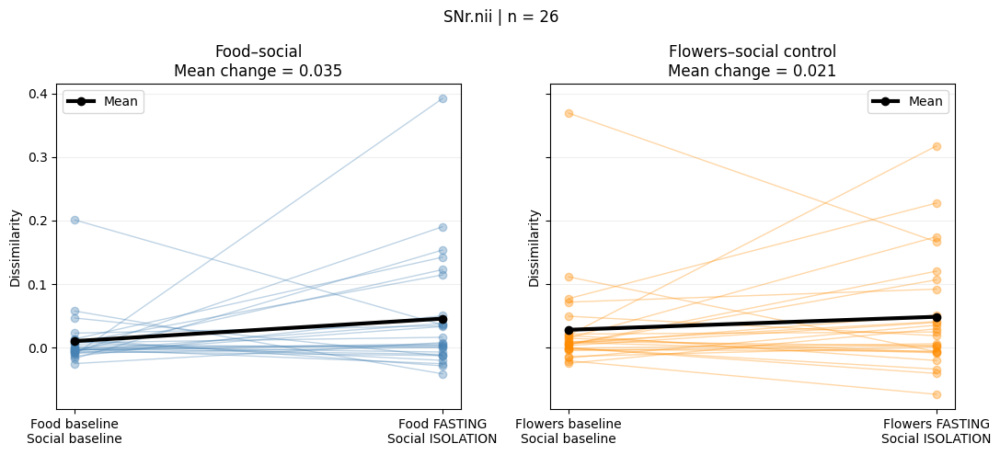

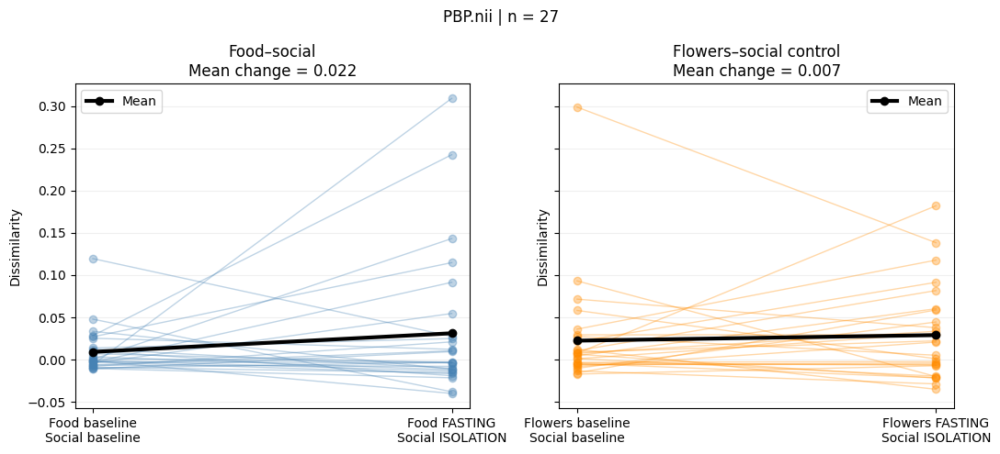

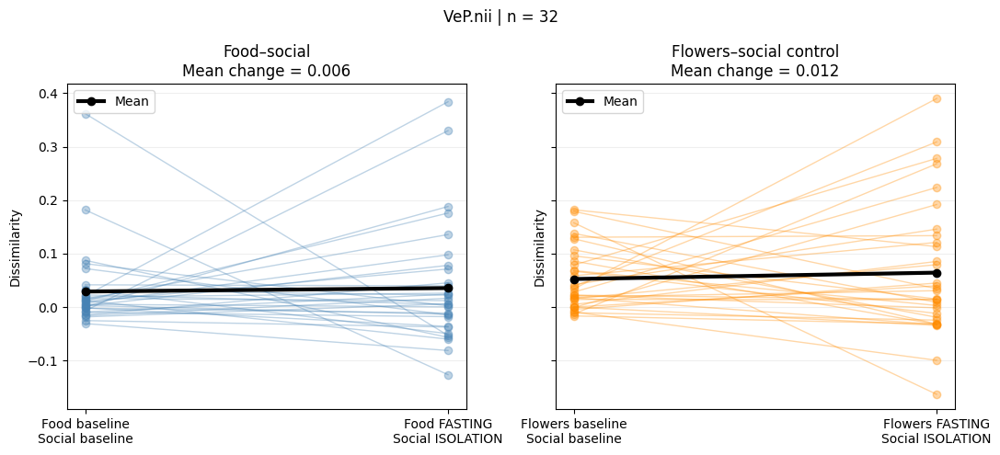

Skipping HN.nii: insufficient complete pairs.


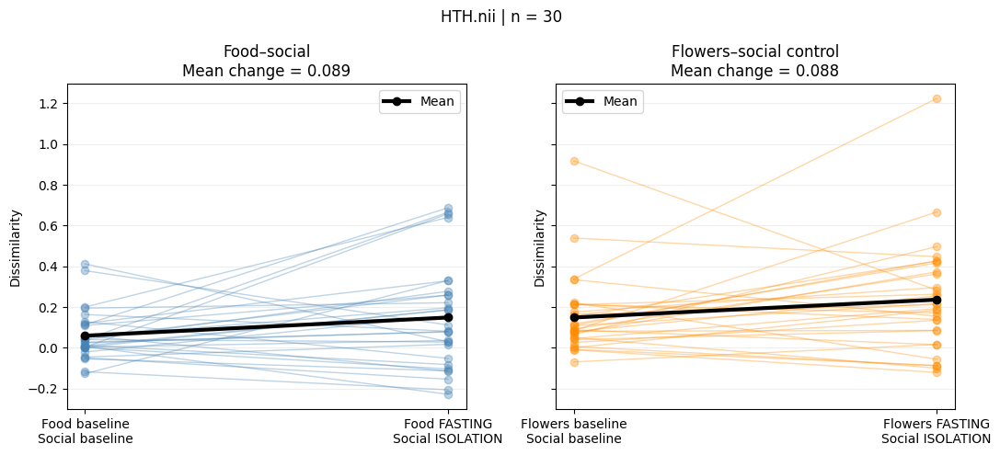

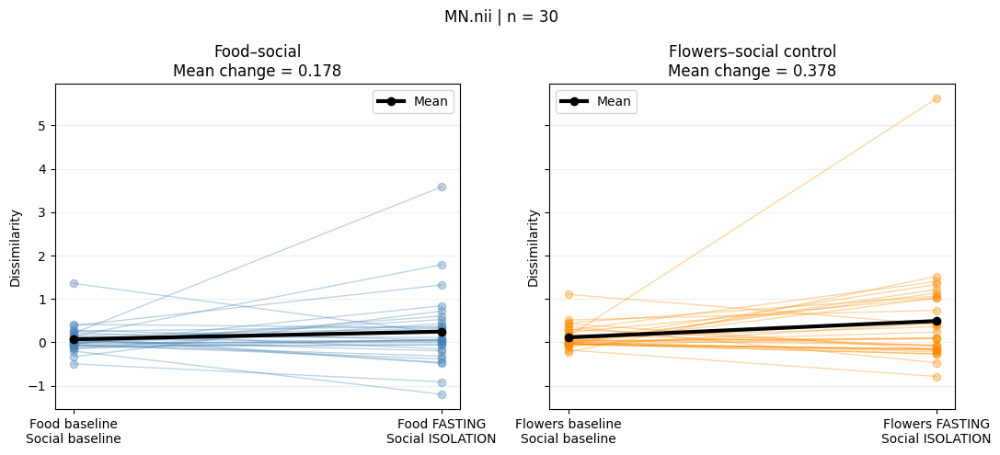

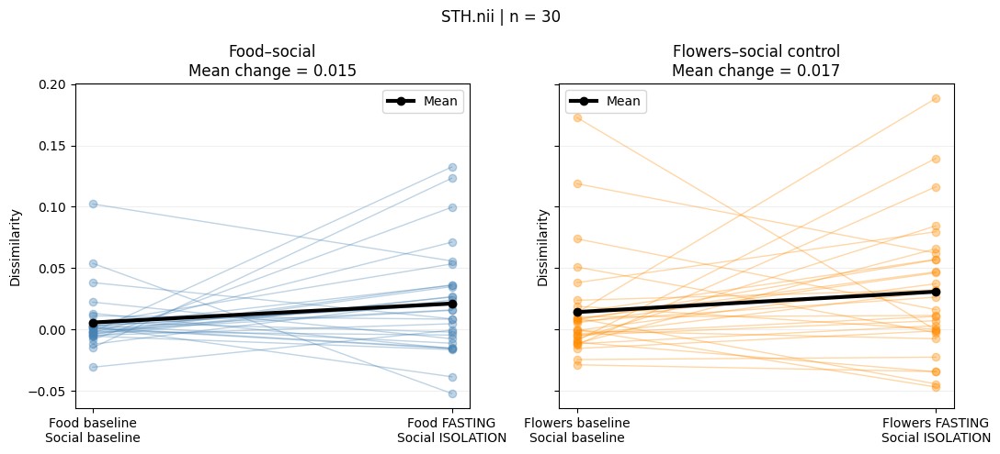

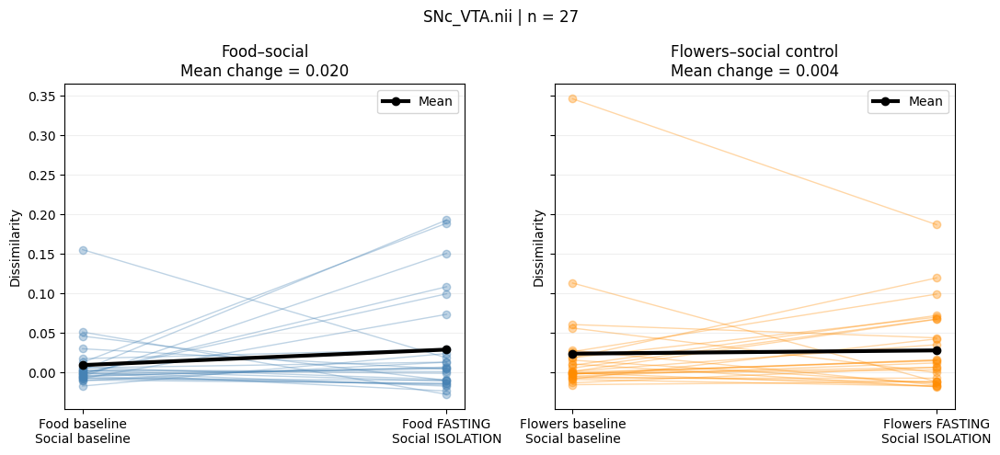

                                                                    ROI  n  food_change  control_change  difference_in_changes    p_food  p_change_difference  p_food_fdr  p_change_difference_fdr
                                                     Insular Cortex.nii 32      0.01063          0.0222               -0.01157    0.8104               0.7442       0.841                   0.9706
                                             Superior Frontal Gyrus.nii 28       0.6434          0.3673                 0.2761 0.0002071              0.04143    0.003796                   0.5696
                                               Middle Frontal Gyrus.nii 31        0.627          0.4651                 0.1619  0.002109               0.1916      0.0145                   0.9579
                          Inferior Frontal Gyrus, pars triangularis.nii  5     -0.09233         0.03035                -0.1227    0.7978                0.744       0.841                   0.9706
                         

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

conds = [str(c) for c in rdms["conditions"]]

def find_condition(cue, state):
    matches = [
        i for i, label in enumerate(conds)
        if {cue, state}.issubset(label.lower().split("_"))
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one condition for {cue} + {state}. "
            f"Available labels: {conds}"
        )
    print(f"{cue}, {state}: {conds[matches[0]]}")
    return matches[0]

food_base = find_condition("food", "baseline")
food_fast = find_condition("food", "fasting")
social_base = find_condition("social", "baseline")
social_iso = find_condition("social", "isolation")
flowers_base = find_condition("flowers", "baseline")
flowers_fast = find_condition("flowers", "fasting")

results = []

for roi_idx, roi_name in enumerate(rdms["rois"]):
    values = []

    for subj_idx in range(len(rdms["subjects"])):
        rdm = rdms["rdms"][subj_idx, roi_idx]

        values.append([
            rdm[food_base, social_base],
            rdm[food_fast, social_iso],       # Cross-condition target
            rdm[flowers_base, social_base],
            rdm[flowers_fast, social_iso],    # Cross-condition control
        ])

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values).all(axis=1)]

    if len(values) < 2:
        print(f"Skipping {roi_name}: insufficient complete pairs.")
        continue

    food_baseline, food_matched, control_baseline, control_matched = values.T

    food_change = food_matched - food_baseline
    control_change = control_matched - control_baseline

    # Does the food–social change differ from the flowers–social change?
    interaction = ttest_rel(food_change, control_change)

    results.append({
        "ROI": str(roi_name),
        "n": len(values),
        "food_change": food_change.mean(),
        "control_change": control_change.mean(),
        "difference_in_changes": (food_change - control_change).mean(),
        "p_food": ttest_rel(food_matched, food_baseline).pvalue,
        "p_change_difference": interaction.pvalue,
    })

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

    panels = [
        (
            food_baseline, food_matched, "Food–social",
            ["Food baseline\nSocial baseline",
             "Food FASTING\nSocial ISOLATION"],
            "steelblue",
        ),
        (
            control_baseline, control_matched, "Flowers–social control",
            ["Flowers baseline\nSocial baseline",
             "Flowers FASTING\nSocial ISOLATION"],
            "darkorange",
        ),
    ]

    for ax, (baseline, matched, title, labels, color) in zip(axes, panels):
        for b, m in zip(baseline, matched):
            ax.plot(
                [0, 1], [b, m],
                "o-", color=color, alpha=0.35, linewidth=1,
            )

        ax.plot(
            [0, 1], [baseline.mean(), matched.mean()],
            "o-", color="black", linewidth=3, label="Mean",
        )

        ax.set_xticks([0, 1], labels)
        ax.set_title(
            f"{title}\nMean change = {(matched - baseline).mean():.3f}"
        )
        ax.set_ylabel("Dissimilarity")
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    fig.suptitle(f"{roi_name} | n = {len(values)}")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results)

# Correct each family of tests across ROIs
if not results_df.empty:
    for column in ["p_food", "p_change_difference"]:
        results_df[column + "_fdr"] = np.nan
        valid = np.isfinite(results_df[column])

        if valid.any():
            results_df.loc[valid, column + "_fdr"] = multipletests(
                results_df.loc[valid, column],
                method="fdr_bh",
            )[1]

    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

In [ ]:
participant_scores

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
0,cortical,sub-SAXSISO01,Insular Cortex,social_vs_food_and_flowers,0.299482,42,17,40,47
1,cortical,sub-SAXSISO01,Insular Cortex,food_vs_social_and_flowers,0.208568,42,17,40,47
2,cortical,sub-SAXSISO01,Insular Cortex,flowers_vs_social_and_food,-0.042783,42,17,40,47
3,cortical,sub-SAXSISO01,Insular Cortex,baseline_vs_deprived,0.310178,42,17,40,47
4,cortical,sub-SAXSISO01,Insular Cortex,isolation_vs_baseline_and_fasting,-0.262047,42,17,40,47
...,...,...,...,...,...,...,...,...,...
14287,midbrain,sub-SAXSISO42,SNc_VTA,isolation_vs_baseline_and_fasting,0.732662,43,6,41,50
14288,midbrain,sub-SAXSISO42,SNc_VTA,fasting_vs_baseline_and_isolation,-0.090914,43,6,41,50
14289,midbrain,sub-SAXSISO42,SNc_VTA,social_isolation_vs_rest_model,0.334453,43,6,41,50
14290,midbrain,sub-SAXSISO42,SNc_VTA,food_fasting_vs_rest_model,0.334453,43,6,41,50


food, baseline: food_baseline
food, fasting: food_fasting
social, baseline: social_baseline
social, isolation: social_isolation
flowers, baseline: flowers_baseline
flowers, fasting: flowers_fasting
flowers, isolation: flowers_isolation
Skipping Frontal Pole.nii: insufficient complete pairs.


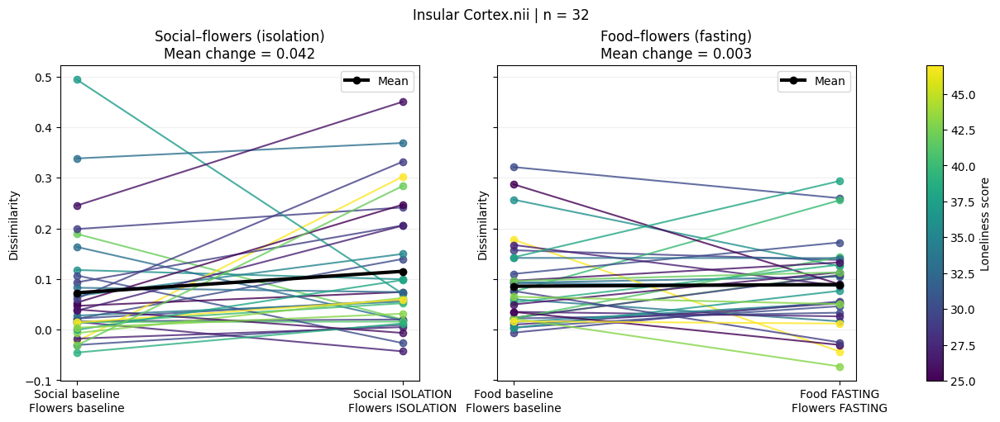

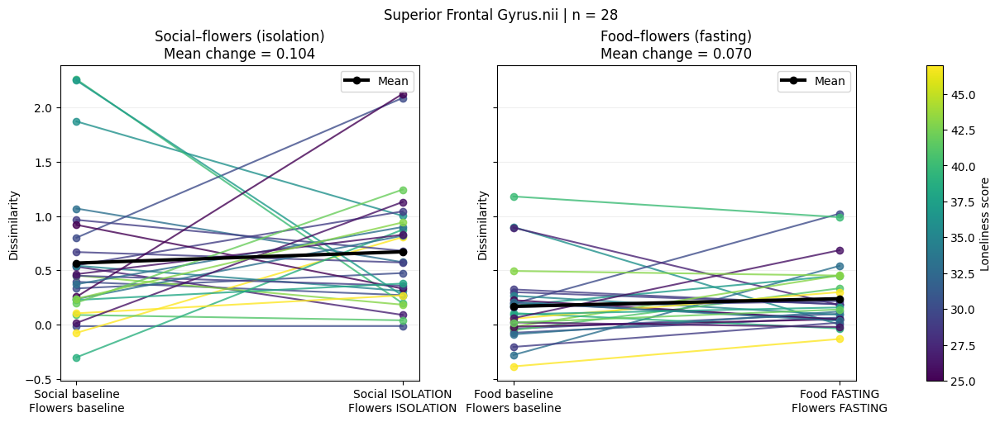

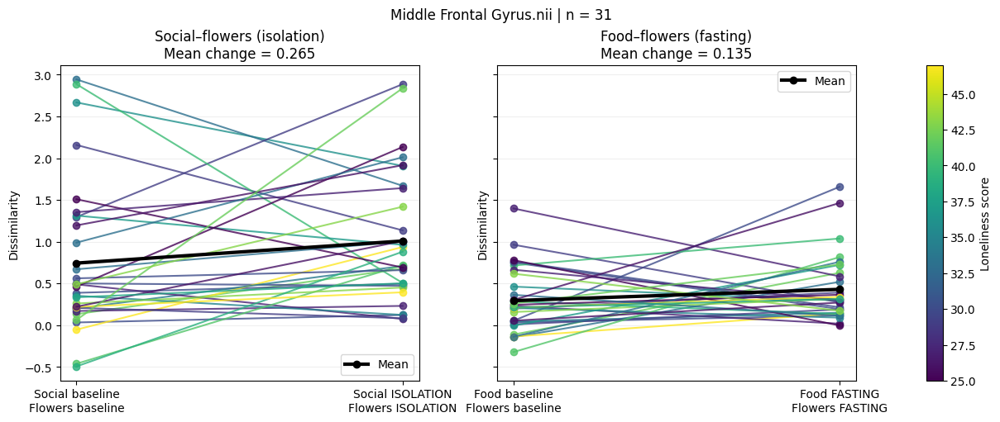

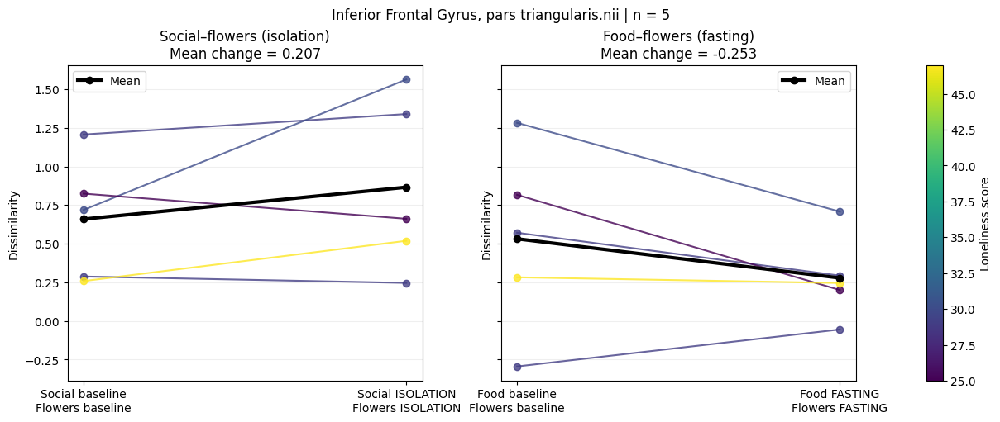

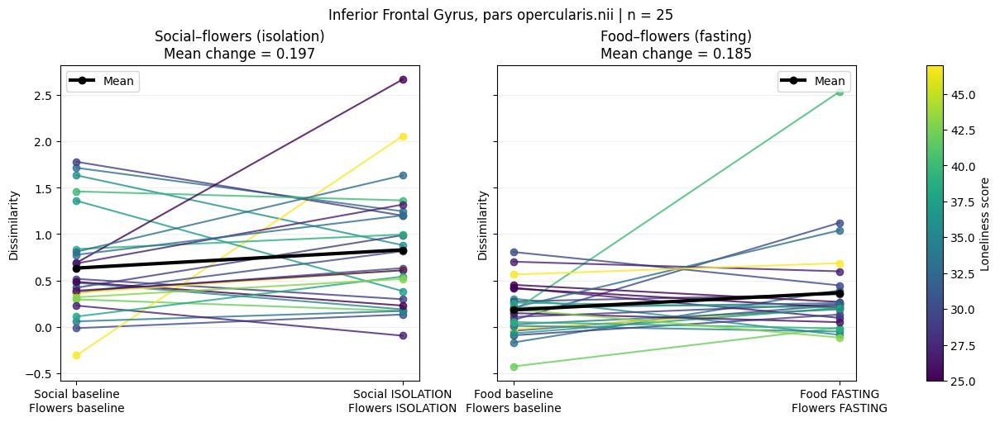

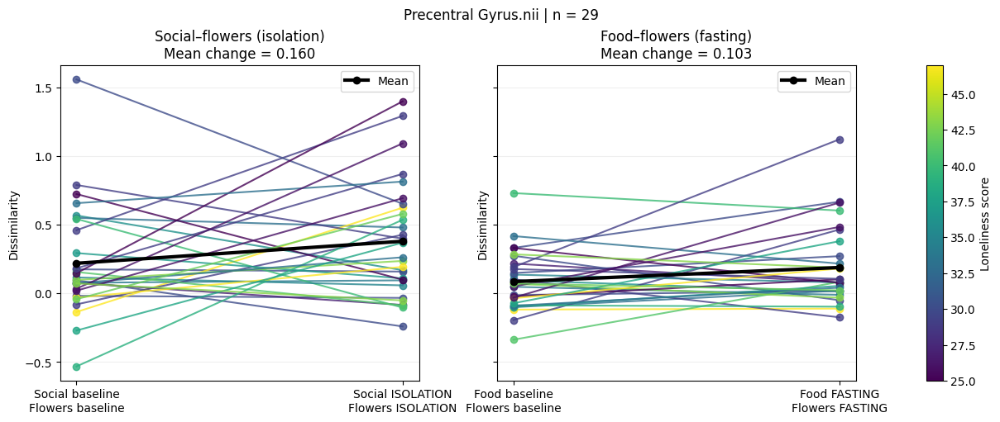

Skipping Temporal Pole.nii: insufficient complete pairs.


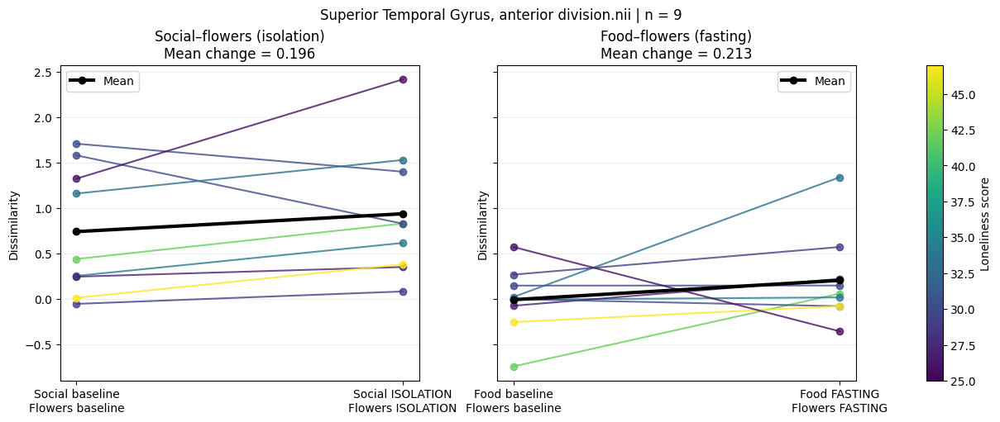

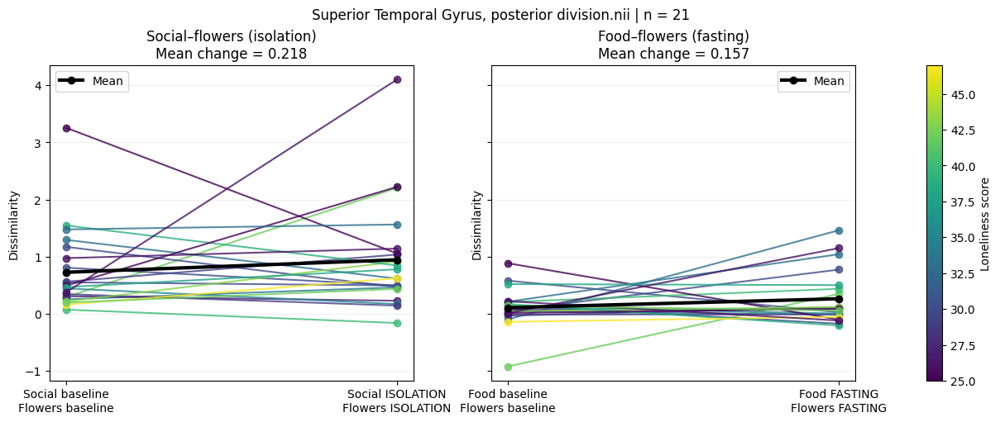

Skipping Middle Temporal Gyrus, anterior division.nii: insufficient complete pairs.
Skipping Middle Temporal Gyrus, posterior division.nii: insufficient complete pairs.
Skipping Middle Temporal Gyrus, temporooccipital part.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, anterior division.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, posterior division.nii: insufficient complete pairs.
Skipping Inferior Temporal Gyrus, temporooccipital part.nii: insufficient complete pairs.


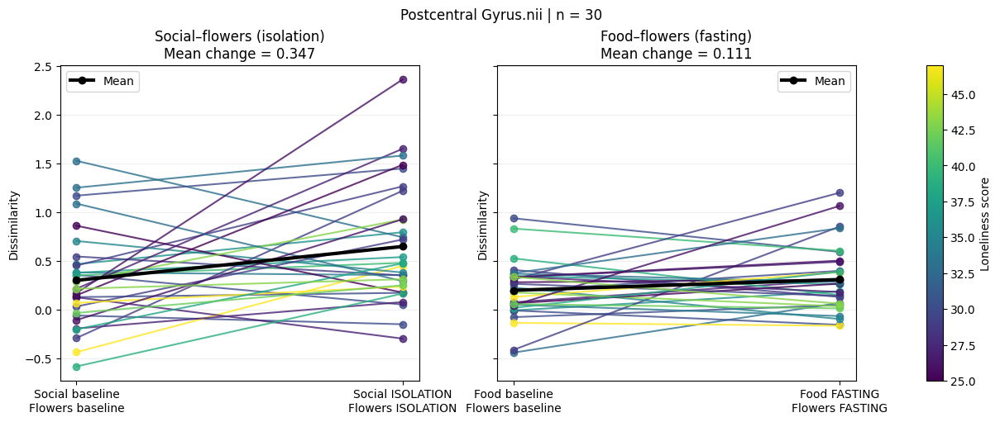

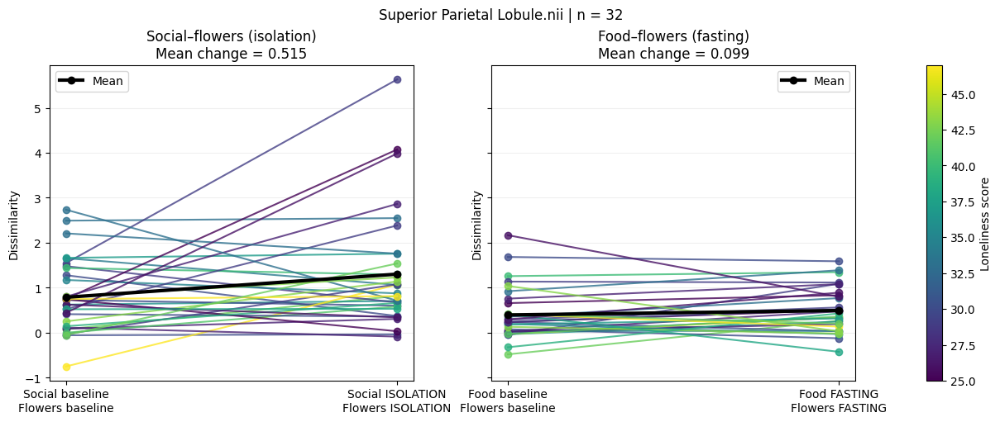

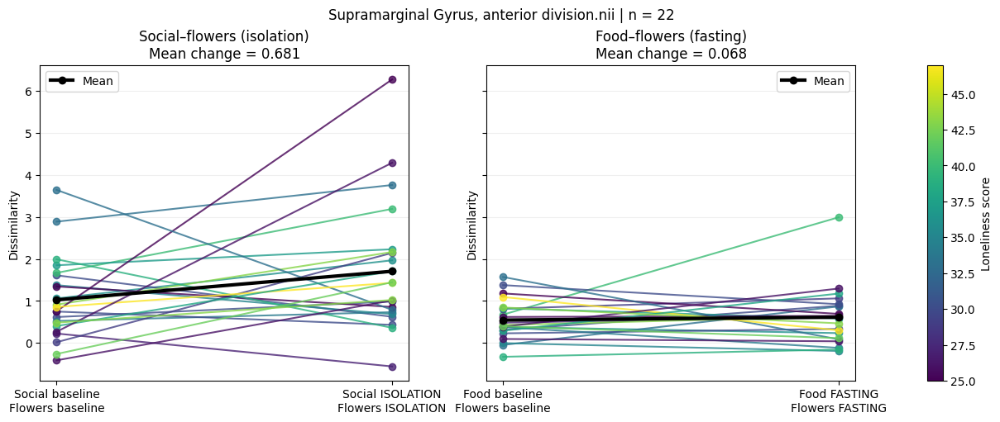

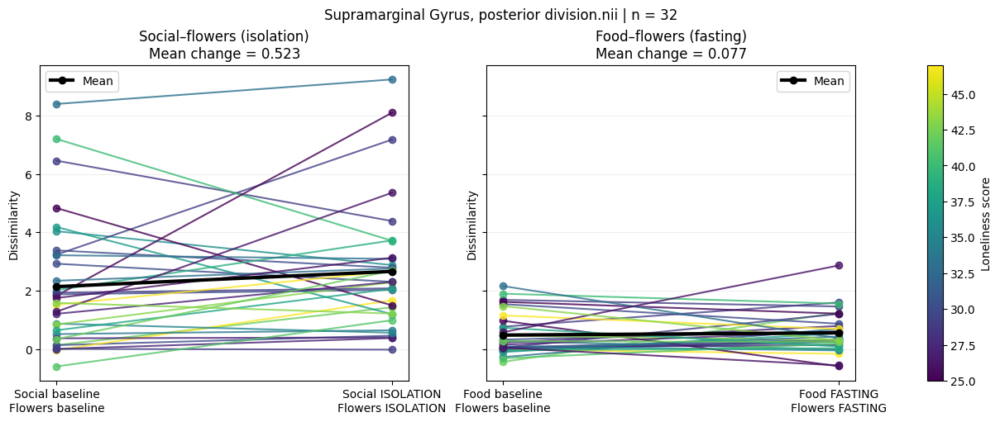

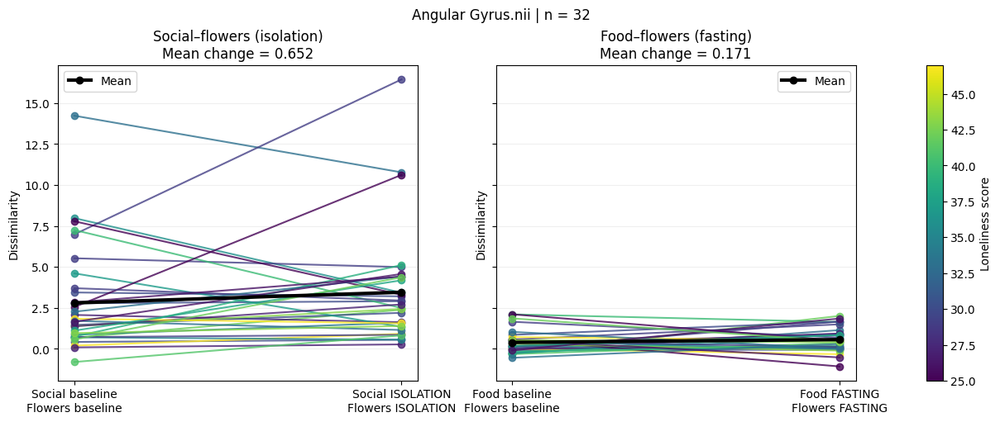

Skipping Lateral Occipital Cortex, superior division.nii: insufficient complete pairs.
Skipping Lateral Occipital Cortex, inferior division.nii: insufficient complete pairs.


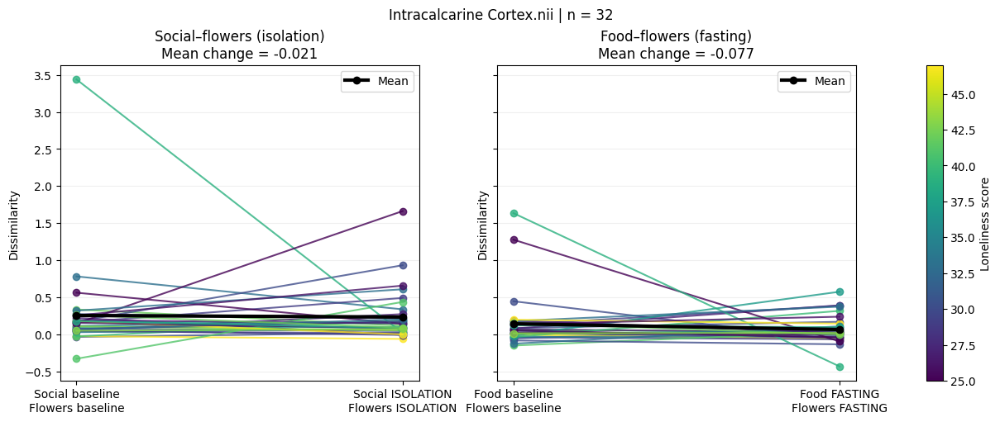

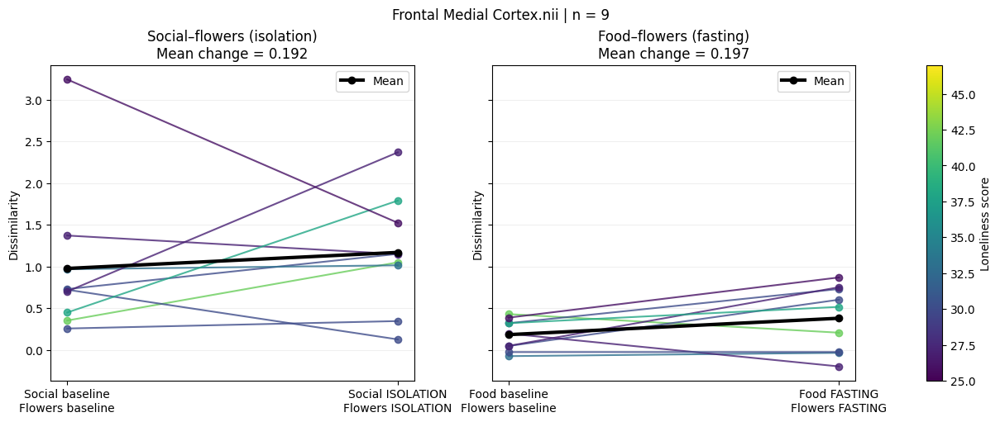

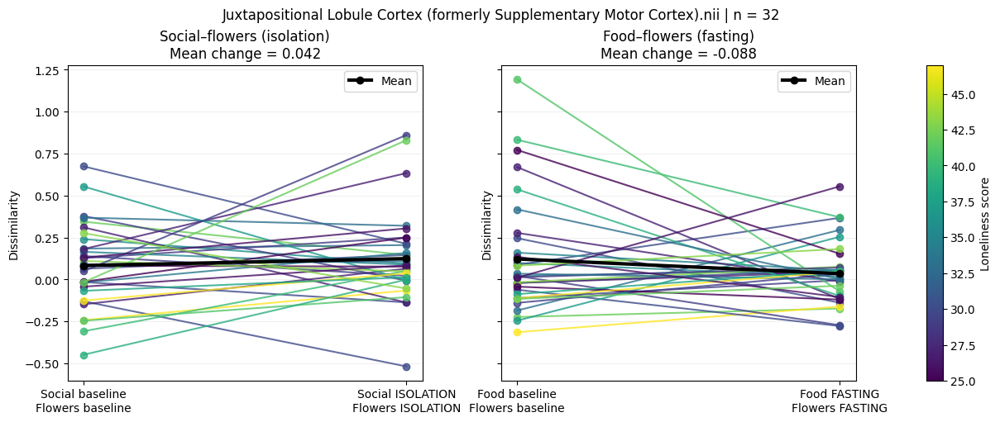

Skipping Subcallosal Cortex.nii: insufficient complete pairs.


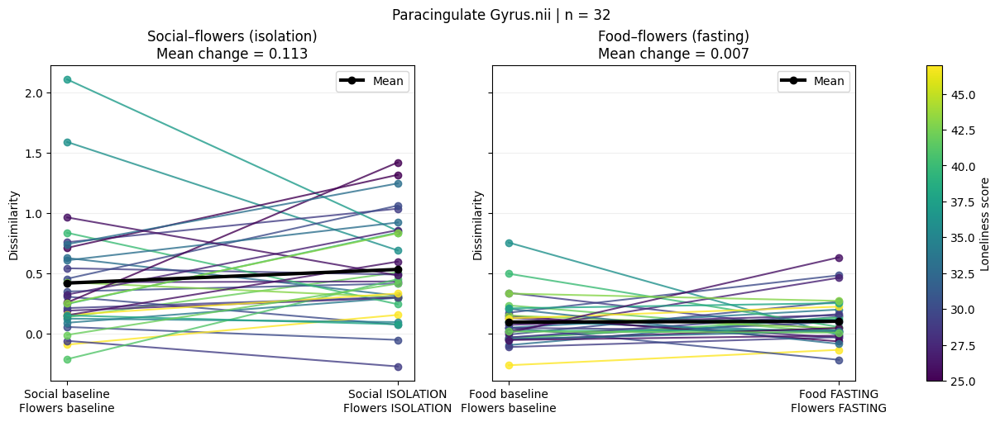

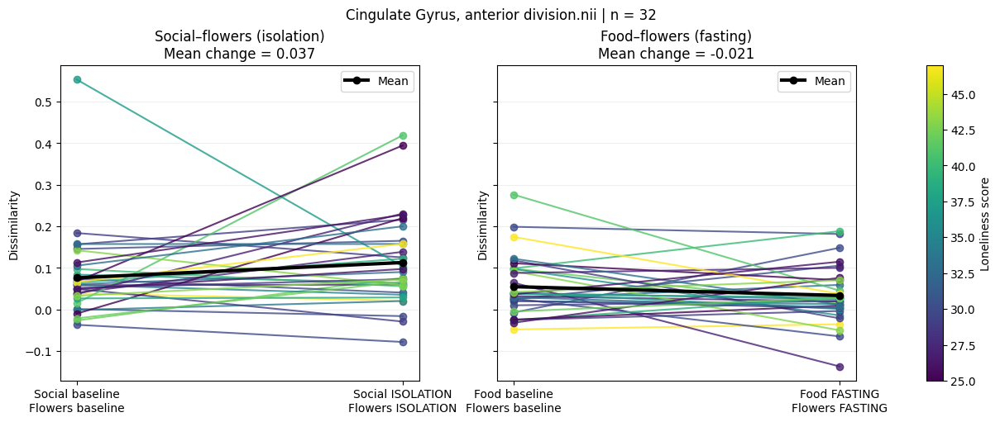

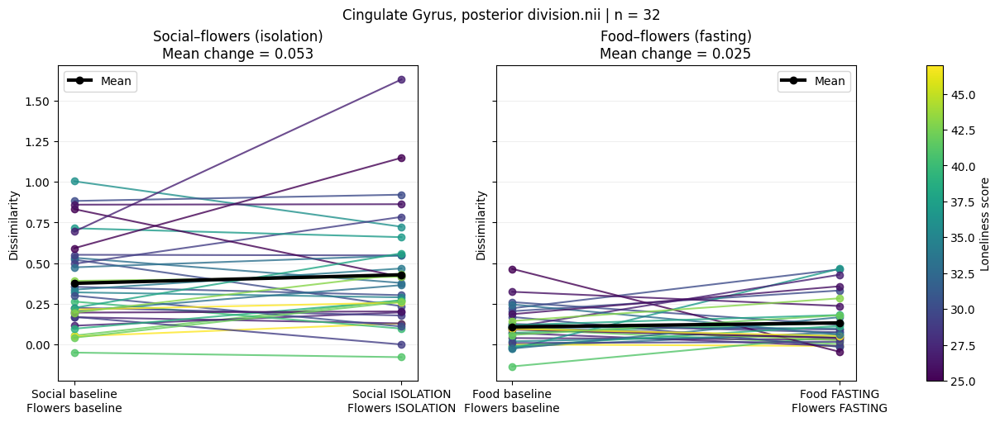

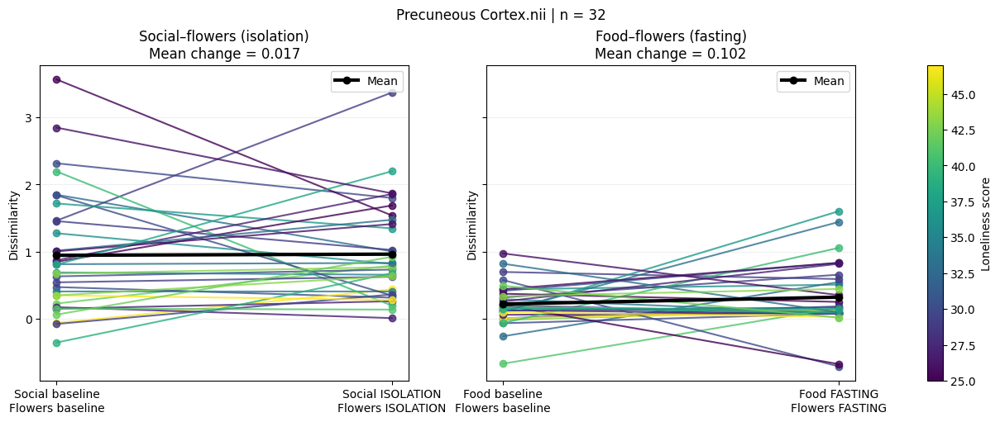

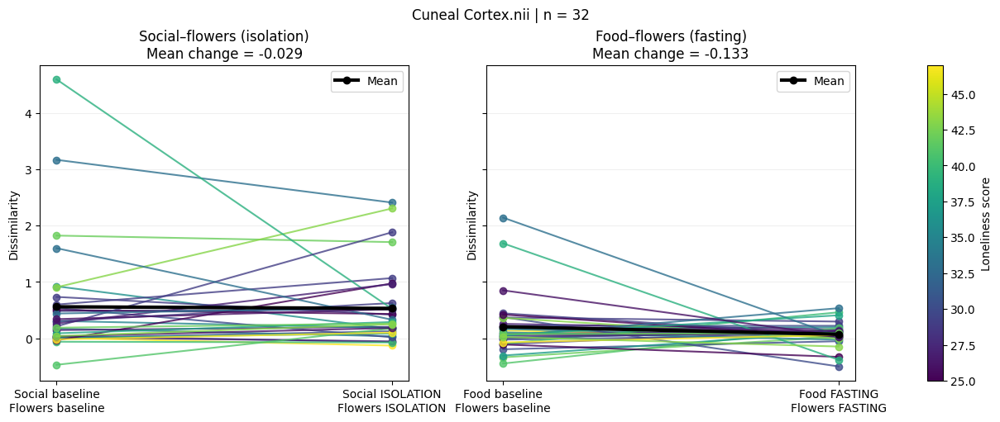

Skipping Frontal Orbital Cortex.nii: insufficient complete pairs.
Skipping Parahippocampal Gyrus, anterior division.nii: insufficient complete pairs.


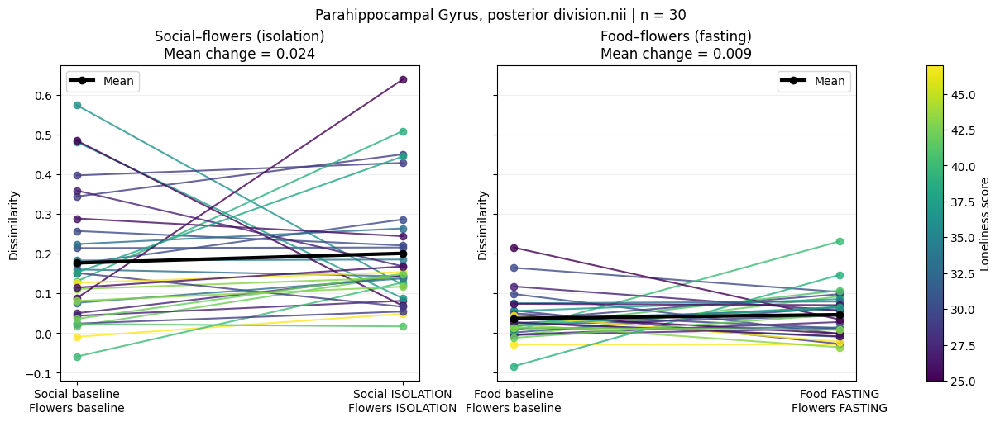

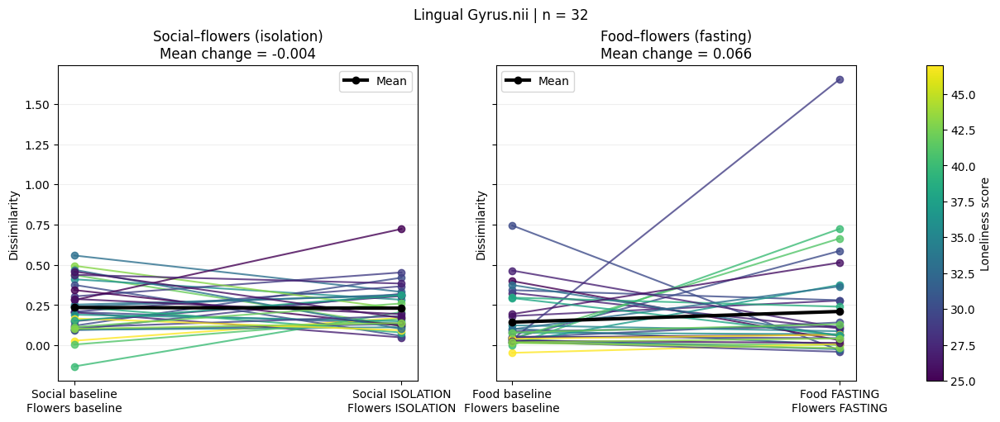

Skipping Temporal Fusiform Cortex, anterior division.nii: insufficient complete pairs.
Skipping Temporal Fusiform Cortex, posterior division.nii: insufficient complete pairs.


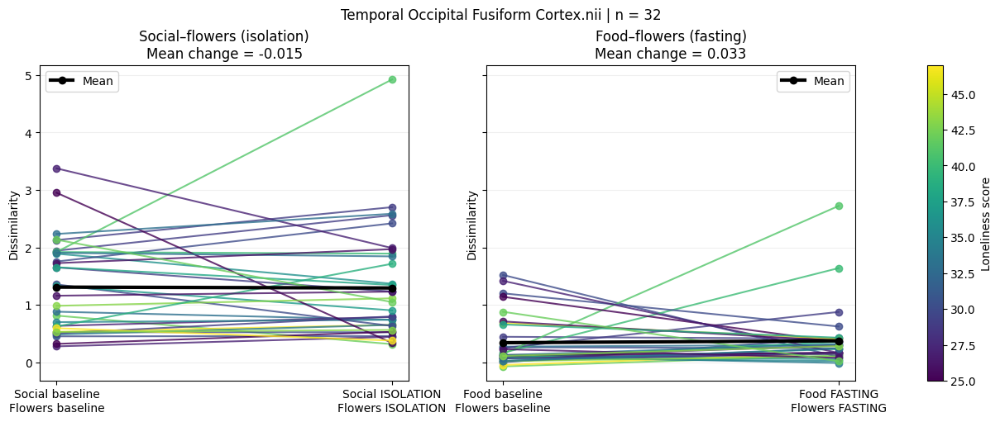

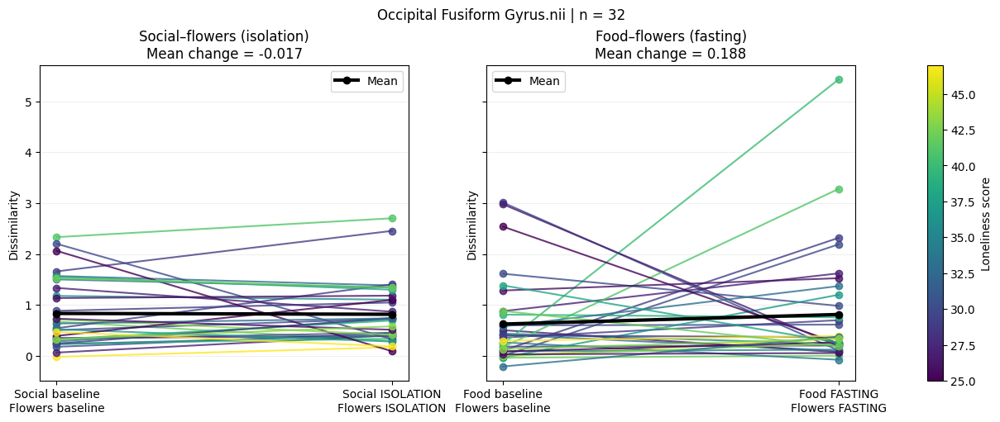

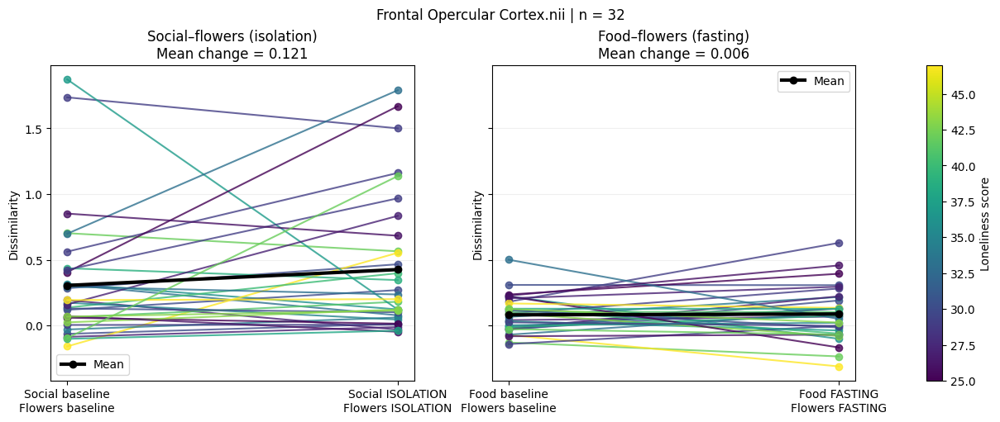

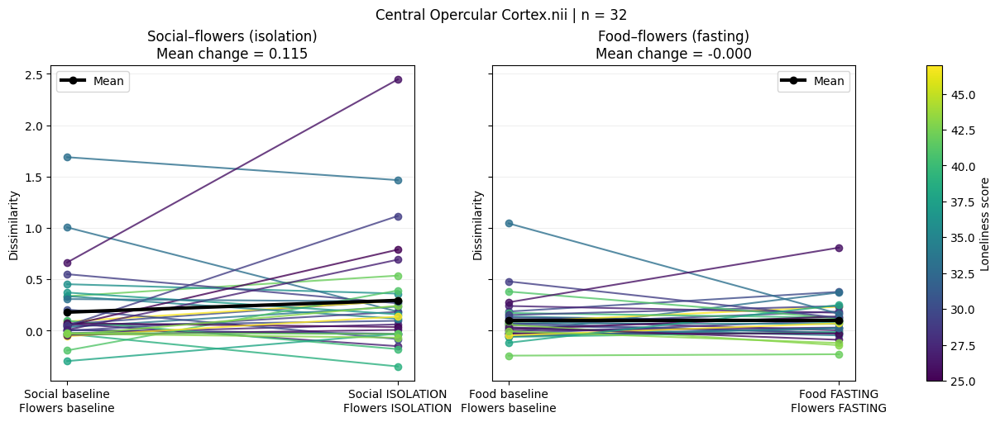

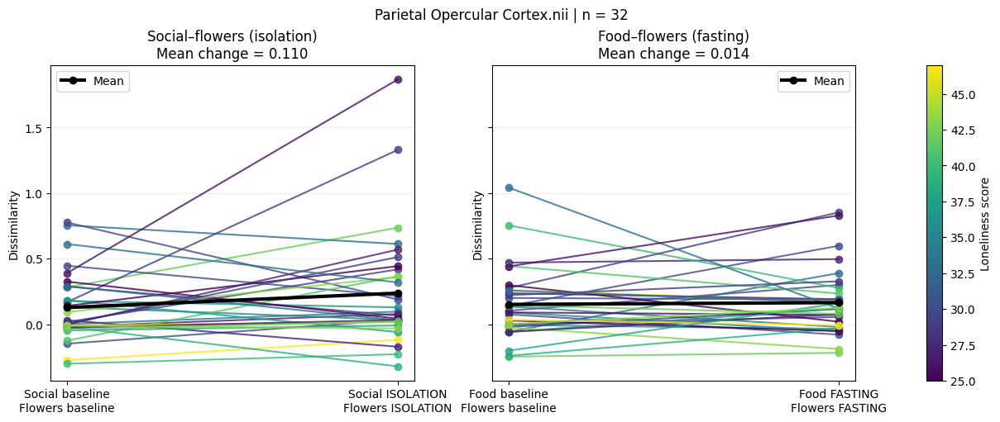

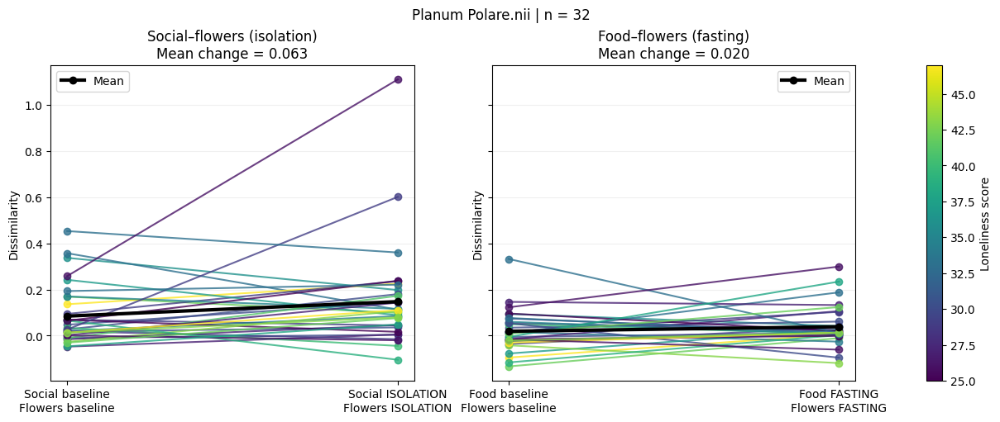

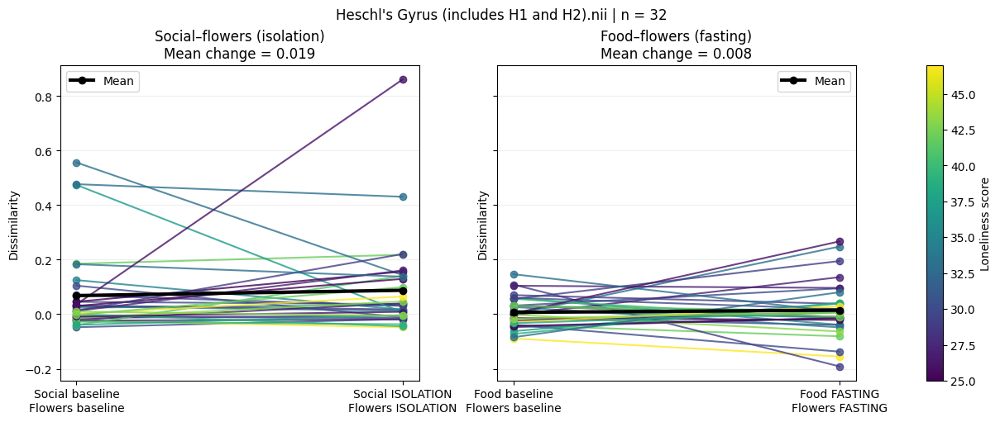

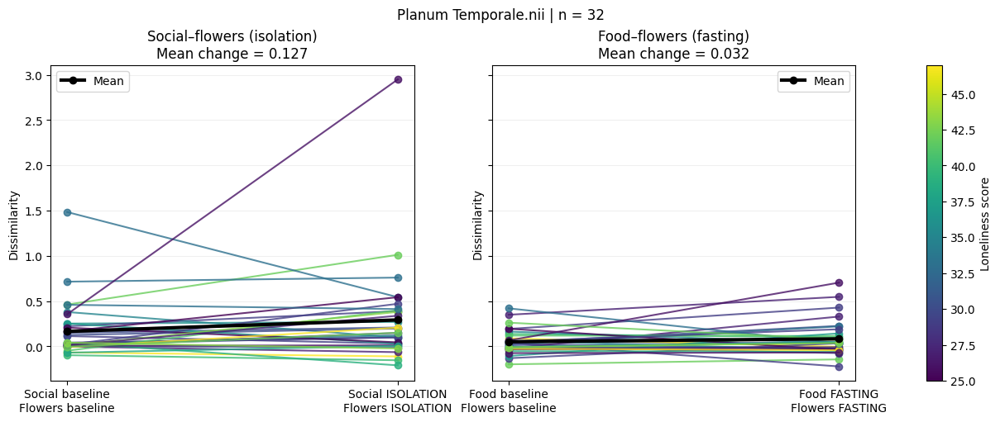

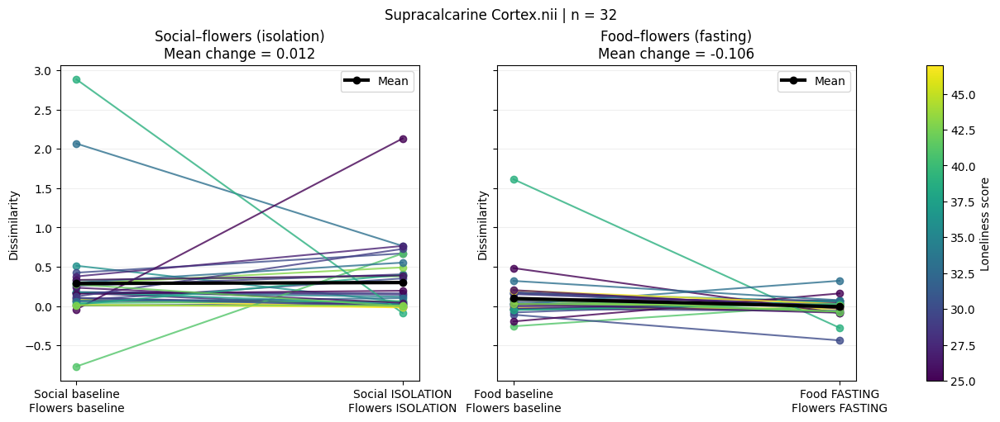

Skipping Occipital Pole.nii: insufficient complete pairs.


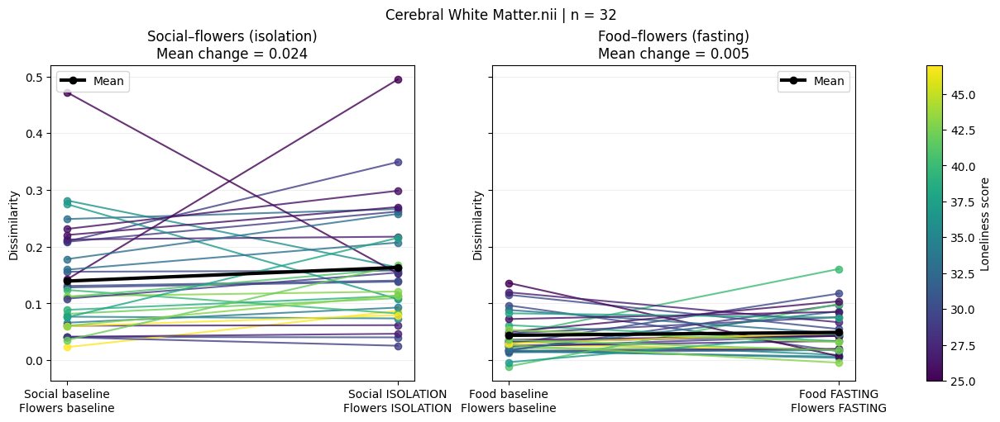

Skipping Cerebral Cortex.nii: insufficient complete pairs.


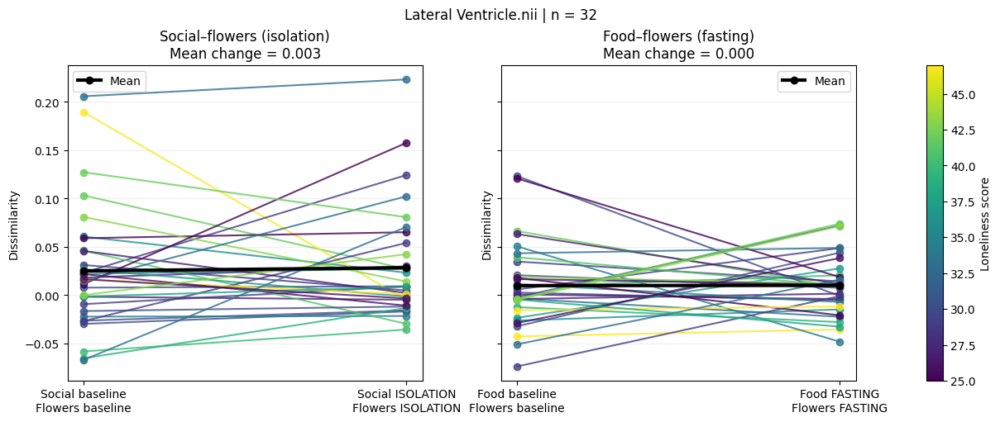

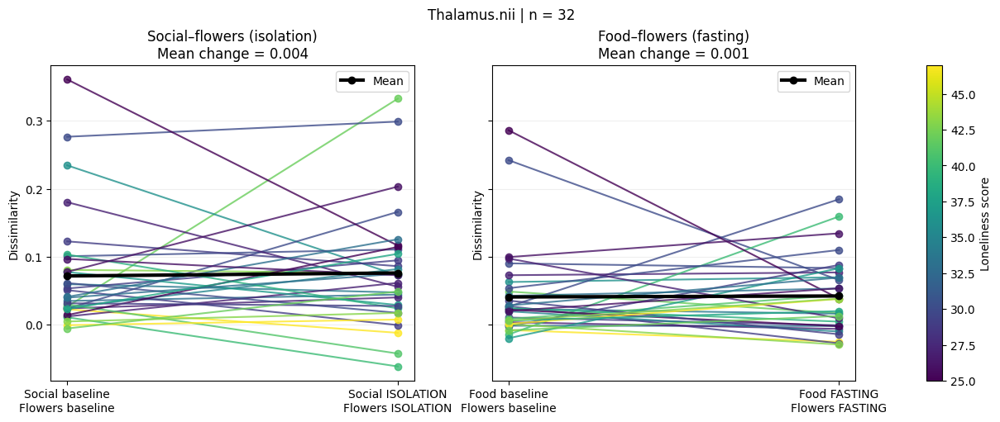

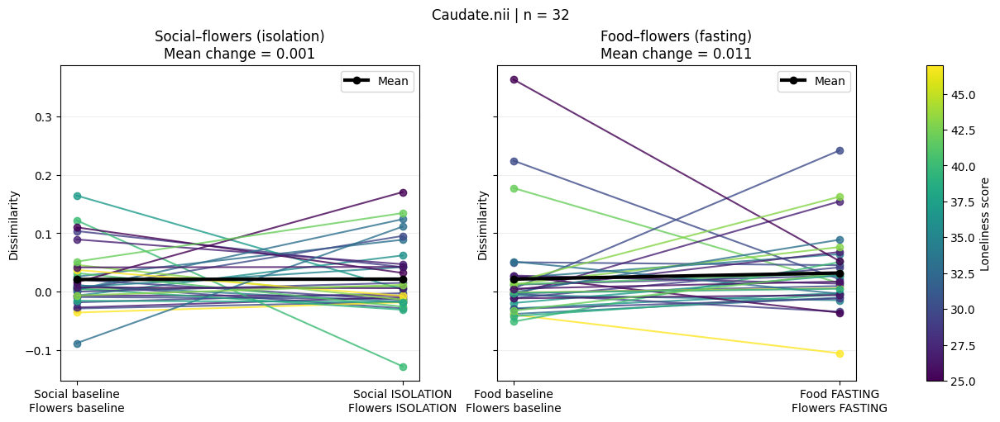

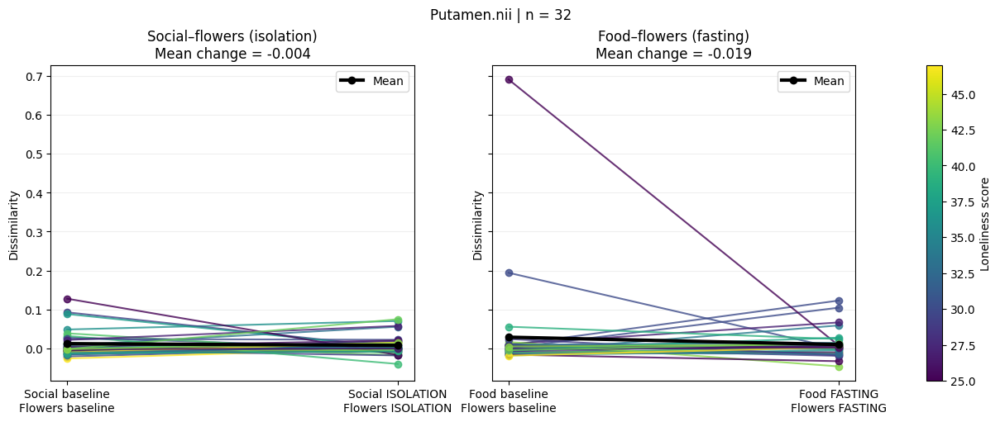

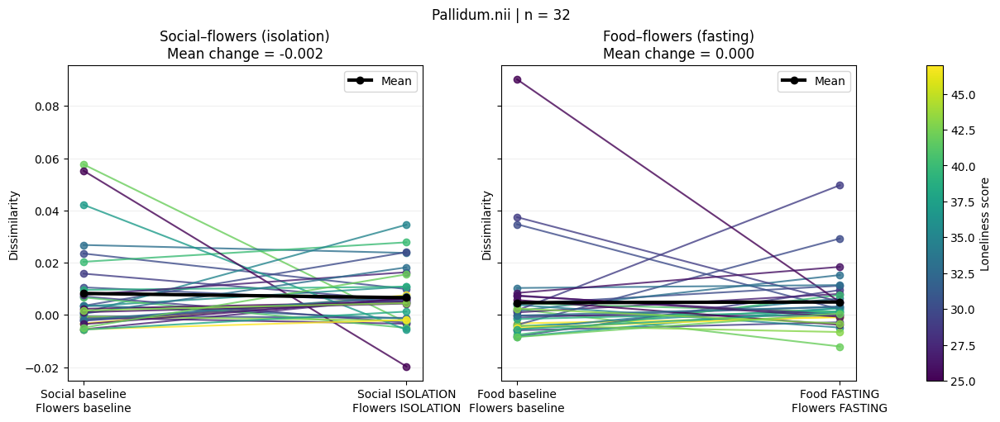

Skipping Brain-Stem.nii: insufficient complete pairs.


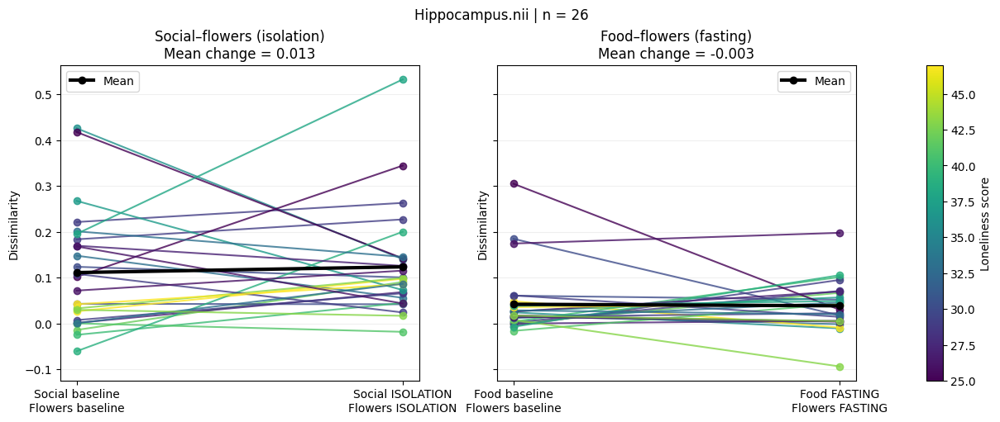

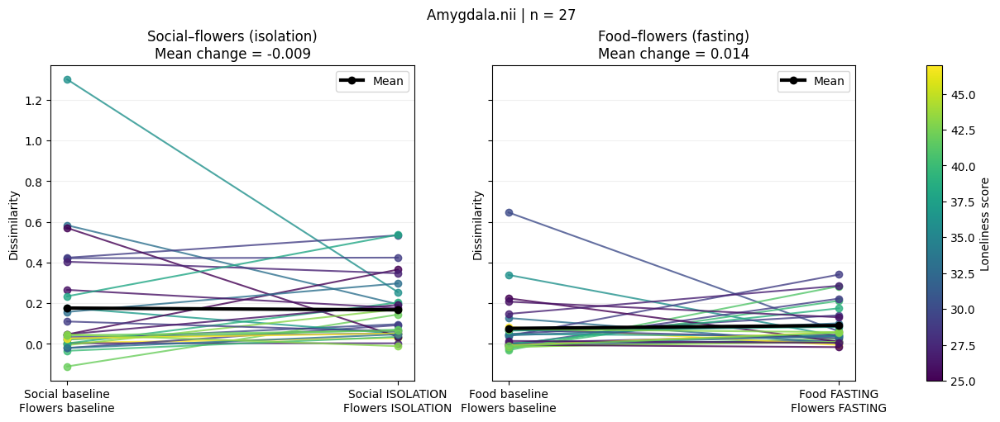

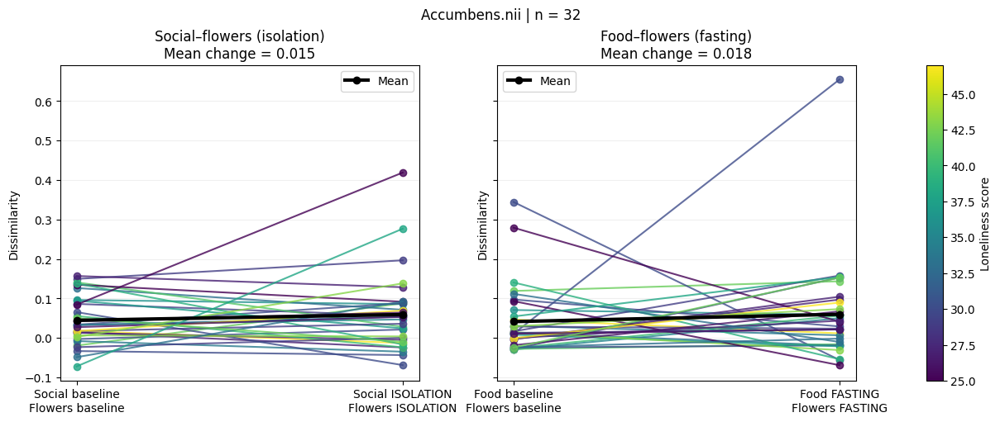

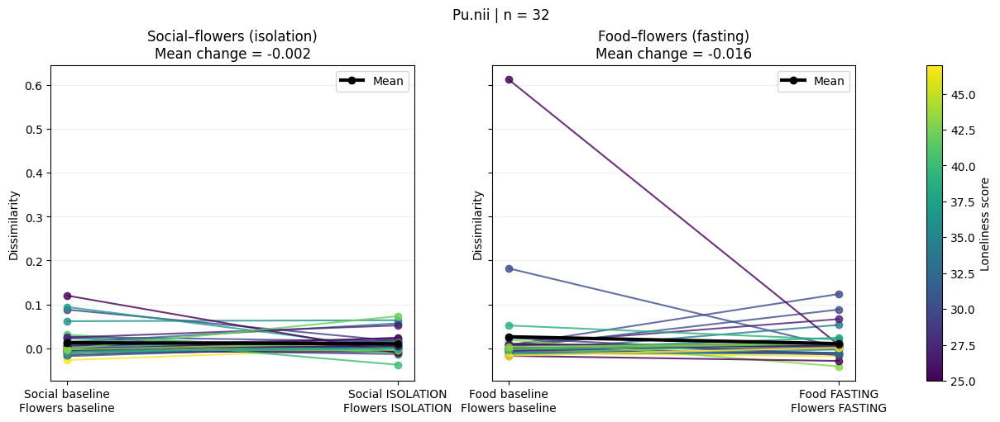

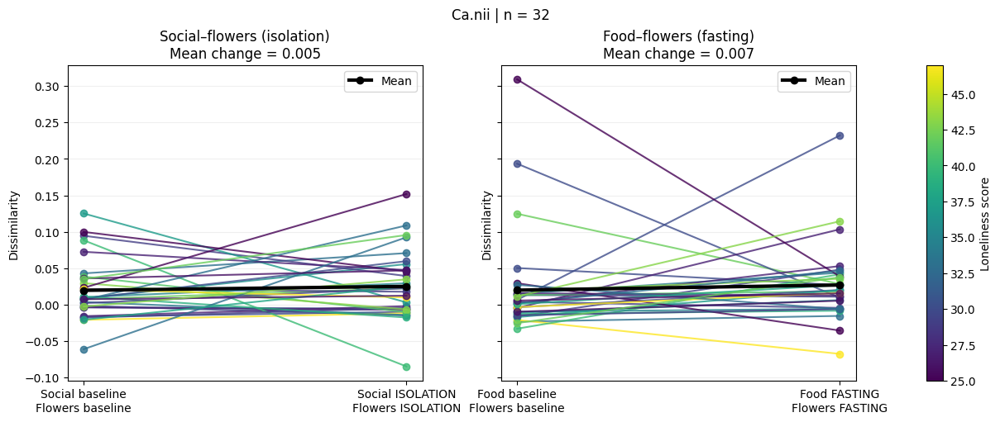

...

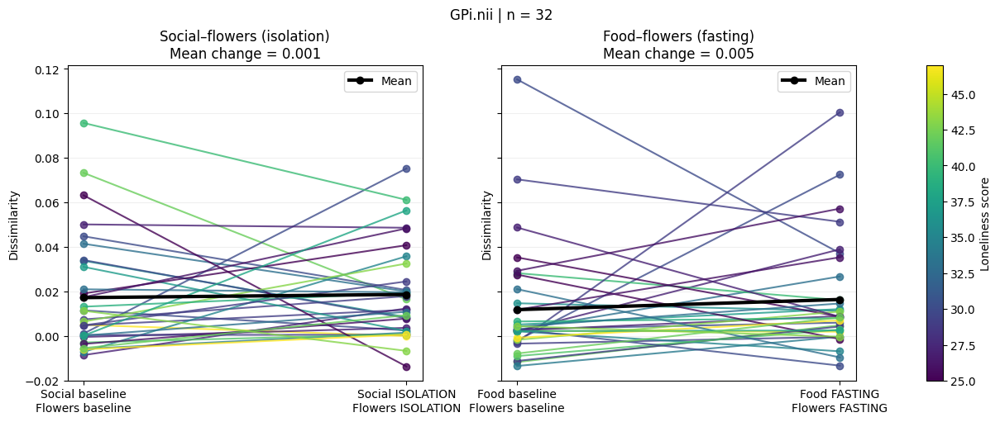

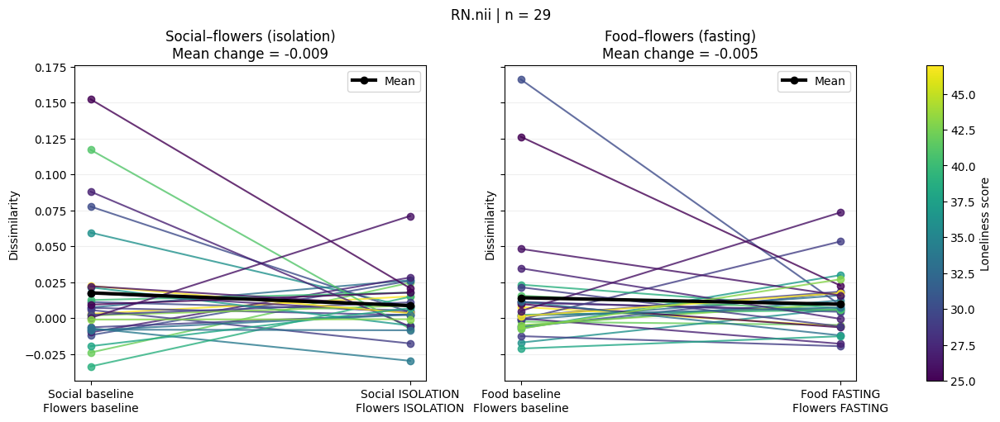

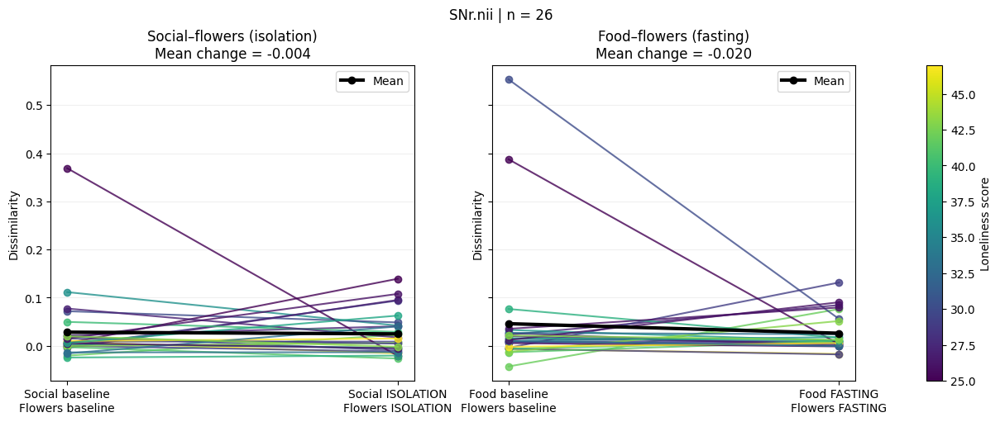

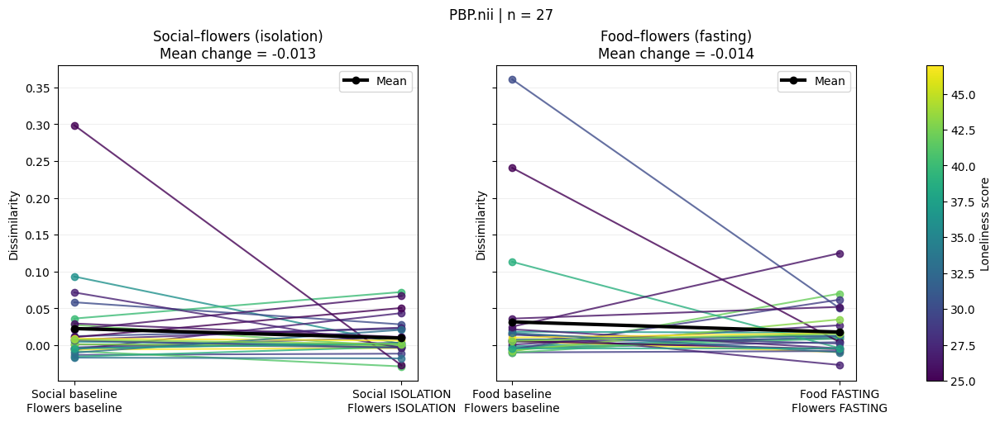

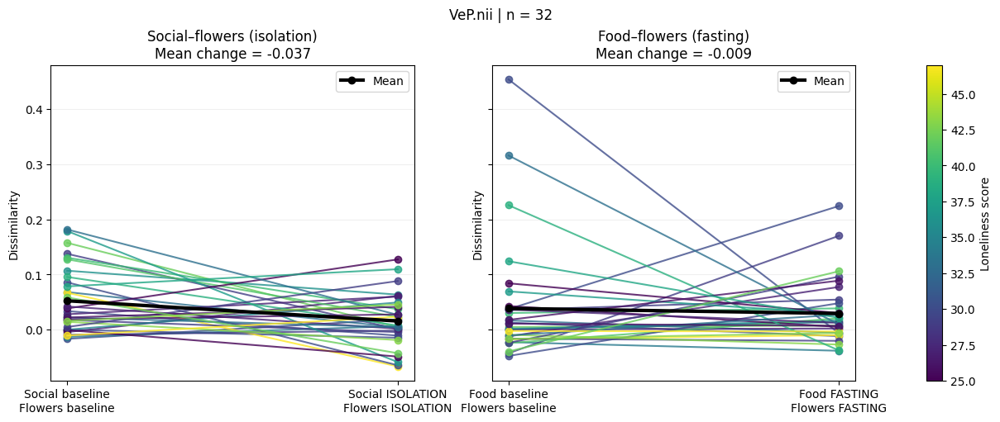

Skipping HN.nii: insufficient complete pairs.


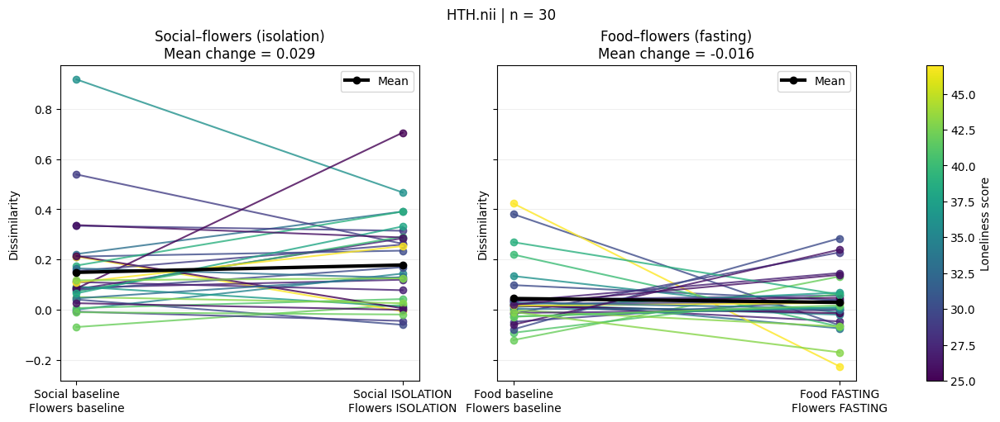

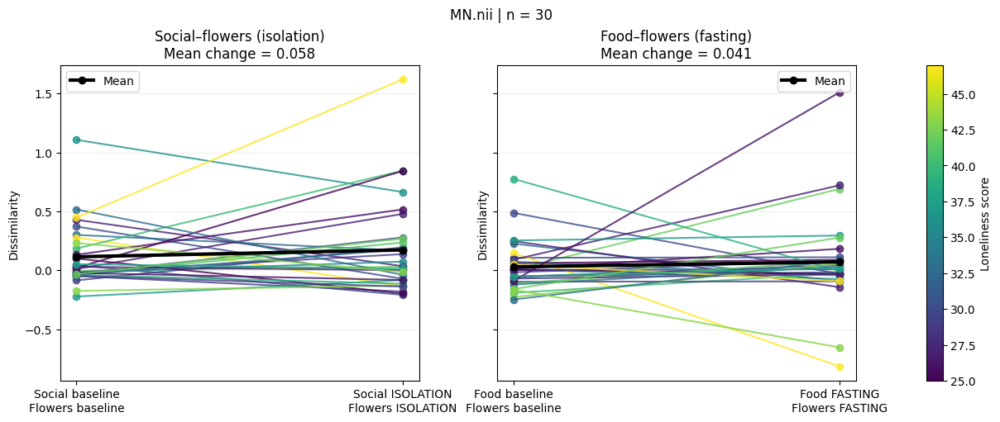

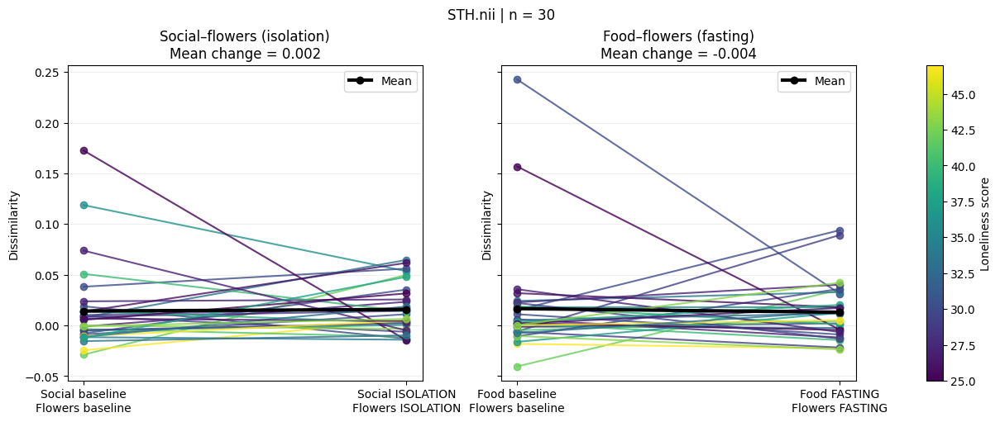

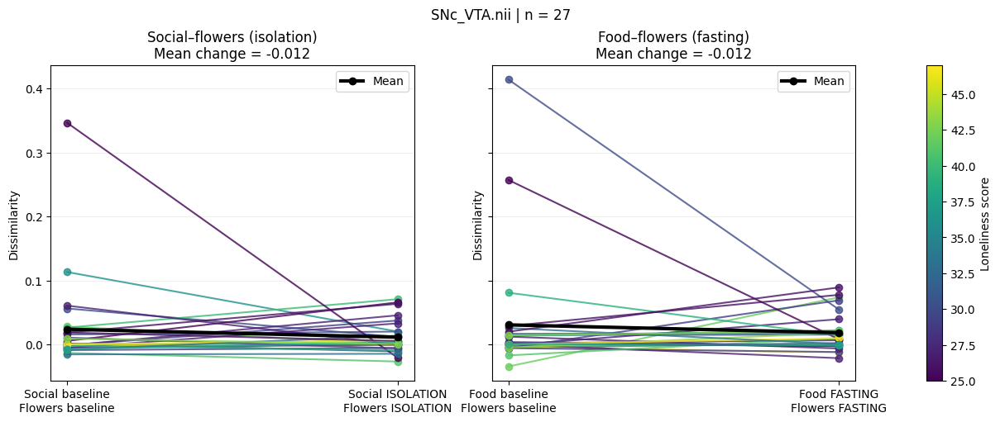

                                                                    ROI  n  isolation_change  fasting_change  difference_in_changes  p_isolation  p_fasting  p_change_difference  p_isolation_fdr  p_fasting_fdr  p_change_difference_fdr
                                                     Insular Cortex.nii 32           0.04247        0.003376                 0.0391       0.1059     0.8348               0.2725           0.6903         0.9415                   0.9897
                                             Superior Frontal Gyrus.nii 28            0.1043         0.07041                0.03388       0.5359     0.3345                0.846           0.8931         0.8667                   0.9897
                                               Middle Frontal Gyrus.nii 31            0.2646          0.1351                 0.1295       0.1443     0.2118                0.486           0.6903         0.8667                   0.9897
                          Inferior Frontal Gyrus, pars triangula

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests


# social_baseline and control_baseline VS social_isolation and control_isolation
# food_baseline and control_baseline VS food_fasting and control_fasting

conds = [str(c) for c in rdms["conditions"]]

def find_condition(cue, state):
    matches = [
        i for i, label in enumerate(conds)
        if {cue, state}.issubset(label.lower().split("_"))
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one condition for {cue} + {state}. "
            f"Available labels: {conds}"
        )
    print(f"{cue}, {state}: {conds[matches[0]]}")
    return matches[0]

food_base = find_condition("food", "baseline")
food_fast = find_condition("food", "fasting")
social_base = find_condition("social", "baseline")
social_iso = find_condition("social", "isolation")
flowers_base = find_condition("flowers", "baseline")
flowers_fast = find_condition("flowers", "fasting")
flowers_iso = find_condition("flowers", "isolation")

# Loneliness score per participant, used to color the lines
loneliness_by_subject = (
    behavioral_df.set_index("subject")["Loneliness_Score"]
    .astype(float)
    .reindex([str(s) for s in rdms["subjects"]])
)
loneliness_cmap = plt.cm.viridis
loneliness_norm = plt.Normalize(
    loneliness_by_subject.min(), loneliness_by_subject.max()
)

results = []

for roi_idx, roi_name in enumerate(rdms["rois"]):
    values = []

    for subj_idx in range(len(rdms["subjects"])):
        rdm = rdms["rdms"][subj_idx, roi_idx]

        values.append([
            rdm[social_base, flowers_base],
            rdm[social_iso, flowers_iso],       
            rdm[food_base, flowers_base],
            rdm[food_fast, flowers_fast],    
        ])

    values = np.asarray(values, dtype=float)
    complete = np.isfinite(values).all(axis=1)
    values = values[complete]
    loneliness = loneliness_by_subject.to_numpy()[complete]

    if len(values) < 2:
        print(f"Skipping {roi_name}: insufficient complete pairs.")
        continue

    social_base_pair, social_iso_pair, food_base_pair, food_fast_pair = values.T

    isolation_change = social_iso_pair - social_base_pair
    fasting_change = food_fast_pair - food_base_pair

    # Does the isolation change (social–flowers) differ from the fasting change (food–flowers)?
    interaction = ttest_rel(isolation_change, fasting_change)

    results.append({
        "ROI": str(roi_name),
        "n": len(values),
        "isolation_change": isolation_change.mean(),
        "fasting_change": fasting_change.mean(),
        "difference_in_changes": (isolation_change - fasting_change).mean(),
        "p_isolation": ttest_rel(social_iso_pair, social_base_pair).pvalue,
        "p_fasting": ttest_rel(food_fast_pair, food_base_pair).pvalue,
        "p_change_difference": interaction.pvalue,
    })

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 5), sharey=True, layout="constrained"
    )

    panels = [
        (
            social_base_pair, social_iso_pair, "Social–flowers (isolation)",
            ["Social baseline\nFlowers baseline",
             "Social ISOLATION\nFlowers ISOLATION"],
        ),
        (
            food_base_pair, food_fast_pair, "Food–flowers (fasting)",
            ["Food baseline\nFlowers baseline",
             "Food FASTING\nFlowers FASTING"],
        ),
    ]

    for ax, (baseline, matched, title, labels) in zip(axes, panels):
        for b, m, score in zip(baseline, matched, loneliness):
            color = (
                loneliness_cmap(loneliness_norm(score))
                if np.isfinite(score) else "lightgrey"
            )
            ax.plot(
                [0, 1], [b, m],
                "o-", color=color, alpha=0.8, linewidth=1.5,
            )

        ax.plot(
            [0, 1], [baseline.mean(), matched.mean()],
            "o-", color="black", linewidth=3, label="Mean", zorder=3,
        )

        ax.set_xticks([0, 1], labels)
        ax.set_title(
            f"{title}\nMean change = {(matched - baseline).mean():.3f}"
        )
        ax.set_ylabel("Dissimilarity")
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    fig.colorbar(
        plt.cm.ScalarMappable(norm=loneliness_norm, cmap=loneliness_cmap),
        ax=axes, label="Loneliness score",
    )
    fig.suptitle(f"{roi_name} | n = {len(values)}")
    plt.show()

results_df = pd.DataFrame(results)

# Correct each family of tests across ROIs
if not results_df.empty:
    for column in ["p_isolation", "p_fasting", "p_change_difference"]:
        results_df[column + "_fdr"] = np.nan
        valid = np.isfinite(results_df[column])

        if valid.any():
            results_df.loc[valid, column + "_fdr"] = multipletests(
                results_df.loc[valid, column],
                method="fdr_bh",
            )[1]

    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))